In [ ]:
import sys, pathlib

#find the project root containing db/dataraflow_db.py

_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query



In [17]:
from db.dataraflow_db import get_connection

conn = get_connection()
print("Database connection established successfully!")
conn.close()

Database connection established successfully!


In [15]:
df = run_query("SELECT * FROM week06.london_2014")
df.head()


,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees<br />
0,2014-1-1,11,8,6,9,7,4,94,86,73,...,31,11,2,40,26,66.0,9.91,4.0,Rain,186<br />
1,2014-1-2,11,9,6,9,6,4,94,81,60,...,31,15,5,32,21,50.0,1.02,2.0,Rain,214<br />
2,2014-1-3,11,8,6,9,5,2,94,76,54,...,31,12,0,50,29,69.0,7.11,2.0,Rain-Thunderstorm,219<br />
3,2014-1-4,9,6,3,8,6,2,93,85,65,...,31,12,5,35,21,39.0,9.91,4.0,Rain,211<br />
4,2014-1-5,12,7,1,11,4,-1,100,88,77,...,31,14,5,35,16,NaN,0.25,5.0,Rain,199<br />


In [22]:
df = run_query("SELECT * FROM week06.london_2014")
df.head()

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees<br />
0,2014-1-1,11,8,6,9,7,4,94,86,73,...,31,11,2,40,26,66.0,9.91,4.0,Rain,186<br />
1,2014-1-2,11,9,6,9,6,4,94,81,60,...,31,15,5,32,21,50.0,1.02,2.0,Rain,214<br />
2,2014-1-3,11,8,6,9,5,2,94,76,54,...,31,12,0,50,29,69.0,7.11,2.0,Rain-Thunderstorm,219<br />
3,2014-1-4,9,6,3,8,6,2,93,85,65,...,31,12,5,35,21,39.0,9.91,4.0,Rain,211<br />
4,2014-1-5,12,7,1,11,4,-1,100,88,77,...,31,14,5,35,16,NaN,0.25,5.0,Rain,199<br />


In [23]:
london = run_query("SELECT * FROM week06.london_2014")
london.head()

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees<br />
0,2014-1-1,11,8,6,9,7,4,94,86,73,...,31,11,2,40,26,66.0,9.91,4.0,Rain,186<br />
1,2014-1-2,11,9,6,9,6,4,94,81,60,...,31,15,5,32,21,50.0,1.02,2.0,Rain,214<br />
2,2014-1-3,11,8,6,9,5,2,94,76,54,...,31,12,0,50,29,69.0,7.11,2.0,Rain-Thunderstorm,219<br />
3,2014-1-4,9,6,3,8,6,2,93,85,65,...,31,12,5,35,21,39.0,9.91,4.0,Rain,211<br />
4,2014-1-5,12,7,1,11,4,-1,100,88,77,...,31,14,5,35,16,NaN,0.25,5.0,Rain,199<br />


In [26]:
cities = run_query("""
    SELECT 'London'    AS city, GMT, [Mean TemperatureC] FROM week06.london_2014
    UNION ALL SELECT 'Beijing',  GMT, [Mean TemperatureC] FROM week06.beijing_pek_2014
    UNION ALL SELECT 'Brasilia', GMT, [Mean TemperatureC] FROM week06.brasilia_bsb_2014
    UNION ALL SELECT 'CapeTown', GMT, [Mean TemperatureC] FROM week06.capetown_cpt_2014
    UNION ALL SELECT 'Delhi',    GMT, [Mean TemperatureC] FROM week06.delhi_del_2014
    UNION ALL SELECT 'Moscow',   GMT, [Mean TemperatureC] FROM week06.moscow_svo_2014
""")
cities.shape   # (2190, 3)

DatabaseError: Execution failed on sql '
    SELECT 'London'    AS city, GMT, [Mean TemperatureC] FROM week06.london_2014
    UNION ALL SELECT 'Beijing',  GMT, [Mean TemperatureC] FROM week06.beijing_pek_2014
    UNION ALL SELECT 'Brasilia', GMT, [Mean TemperatureC] FROM week06.brasilia_bsb_2014
    UNION ALL SELECT 'CapeTown', GMT, [Mean TemperatureC] FROM week06.capetown_cpt_2014
    UNION ALL SELECT 'Delhi',    GMT, [Mean TemperatureC] FROM week06.delhi_del_2014
    UNION ALL SELECT 'Moscow',   GMT, [Mean TemperatureC] FROM week06.moscow_svo_2014
': (pymssql.exceptions.ProgrammingError) (207, b"Invalid column name 'GMT'.DB-Lib error message 20018, severity 16:\nGeneral SQL Server error: Check messages from the SQL Server\nDB-Lib error message 20018, severity 16:\nGeneral SQL Server error: Check messages from the SQL Server\nDB-Lib error message 20018, severity 16:\nGeneral SQL Server error: Check messages from the SQL Server\nDB-Lib error message 20018, severity 16:\nGeneral SQL Ser

In [27]:
london = run_query("SELECT * FROM week06.london_2014")
print(london.columns.tolist())

['GMT', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC', 'Dew PointC', 'MeanDew PointC', 'Min DewpointC', 'Max Humidity', ' Mean Humidity', ' Min Humidity', ' Max Sea Level PressurehPa', ' Mean Sea Level PressurehPa', ' Min Sea Level PressurehPa', ' Max VisibilityKm', ' Mean VisibilityKm', ' Min VisibilitykM', ' Max Wind SpeedKm/h', ' Mean Wind SpeedKm/h', ' Max Gust SpeedKm/h', 'Precipitationmm', ' CloudCover', ' Events', 'WindDirDegrees<br />']


In [28]:
print("Beijing:", run_query("SELECT TOP 1 * FROM week06.beijing_pek_2014").columns.tolist())
print("Brasilia:", run_query("SELECT TOP 1 * FROM week06.brasilia_bsb_2014").columns.tolist())
print("CapeTown:", run_query("SELECT TOP 1 * FROM week06.capetown_cpt_2014").columns.tolist())
print("Delhi:", run_query("SELECT TOP 1 * FROM week06.delhi_del_2014").columns.tolist())
print("Moscow:", run_query("SELECT TOP 1 * FROM week06.moscow_svo_2014").columns.tolist())

Beijing: ['Date', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC', 'Dew PointC', 'MeanDew PointC', 'Min DewpointC', 'Max Humidity', ' Mean Humidity', ' Min Humidity', ' Max Sea Level PressurehPa', ' Mean Sea Level PressurehPa', ' Min Sea Level PressurehPa', ' Max VisibilityKm', ' Mean VisibilityKm', ' Min VisibilitykM', ' Max Wind SpeedKm/h', ' Mean Wind SpeedKm/h', ' Max Gust SpeedKm/h', 'Precipitationmm', ' CloudCover', ' Events', 'WindDirDegrees<br />']
Brasilia: ['Date', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC', 'Dew PointC', 'MeanDew PointC', 'Min DewpointC', 'Max Humidity', ' Mean Humidity', ' Min Humidity', ' Max Sea Level PressurehPa', ' Mean Sea Level PressurehPa', ' Min Sea Level PressurehPa', ' Max VisibilityKm', ' Mean VisibilityKm', ' Min VisibilitykM', ' Max Wind SpeedKm/h', ' Mean Wind SpeedKm/h', ' Max Gust SpeedKm/h', 'Precipitationmm', ' CloudCover', ' Events', 'WindDirDegrees<br />']
CapeTown: ['Date', 'Max TemperatureC', 'Mean Temperat

In [30]:
# UNION ALL combines or stacks multiple tables into one long Dataframe.  

cities = run_query("""
    SELECT 'London'    AS city, GMT AS Date, [Mean TemperatureC] FROM week06.london_2014
    UNION ALL SELECT 'Beijing',  Date, [Mean TemperatureC] FROM week06.beijing_pek_2014
    UNION ALL SELECT 'Brasilia', Date, [Mean TemperatureC] FROM week06.brasilia_bsb_2014
    UNION ALL SELECT 'CapeTown', Date, [Mean TemperatureC] FROM week06.capetown_cpt_2014
    UNION ALL SELECT 'Delhi',    Date, [Mean TemperatureC] FROM week06.delhi_del_2014
    UNION ALL SELECT 'Moscow',   Date, [Mean TemperatureC] FROM week06.moscow_svo_2014
""")
cities.shape

(2190, 3)

In [35]:
# computing Aggregate

avg_by_city = run_query("""
    SELECT 'London' AS city, AVG([Mean TemperatureC]) AS avg_temp FROM week06.london_2014
    UNION ALL SELECT 'Delhi', AVG([Mean TemperatureC]) FROM week06.delhi_del_2014
""")
print(avg_by_city)


     city  avg_temp
0  London        12
1   Delhi        13


In [41]:
# pull raw rows and aggregate in pandas

cities.groupby("city")["Mean TemperatureC"].mean()




city
Beijing     13.364384
Brasilia    22.895890
CapeTown    17.567123
Delhi       13.709589
London      12.328767
Moscow       5.994521
Name: Mean TemperatureC, dtype: float64

In [44]:
cities.to_csv("cities_mean_temp.csv", index=False)

In [45]:
who = run_query("SELECT * FROM week06.who_pop_tb_all")
who.head()

,Country,Population (1000s),TB deaths
0,Afghanistan,30552,13000.00
1,Albania,3173,20.00
2,Algeria,39208,5100.00
3,Andorra,79,0.26
4,Angola,21472,6900.00


In [ ]:
# Intermediate SQL for Data Analysts


# --- Connect to the cohort database (read-only) ---
import sys, pathlib, re
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query, get_engine, get_connection

import pandas as pd
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

_BLOCKED = re.compile(
    r"\b(INSERT|UPDATE|DELETE|MERGE|DROP|ALTER|CREATE|TRUNCATE|EXEC|EXECUTE|GRANT|REVOKE|DENY|INTO|BACKUP|RESTORE)\b",
    re.IGNORECASE,
)

def q(sql: str) -> pd.DataFrame:
    """Run a read-only query and return a DataFrame.

    String literals and comments are stripped before the safety check, so a value
    like 'Delete me' inside quotes is fine.
    """
    scrubbed = re.sub(r"'([^']|'')*'", "''", sql)           # string literals
    scrubbed = re.sub(r"--[^\n]*", "", scrubbed)              # -- comments
    scrubbed = re.sub(r"/\*.*?\*/", "", scrubbed, flags=re.S) # /* comments */
    hit = _BLOCKED.search(scrubbed)
    if hit:
        raise PermissionError(
            f"'{hit.group(0).upper()}' is not allowed: this notebook is read-only. "
            "Shape your data inside the SELECT, or in pandas."
        )
    return run_query(sql)

q("SELECT DB_NAME() AS database_name, CURRENT_USER AS logged_in_as, SYSDATETIME() AS server_time")



,database_name,logged_in_as,server_time
0,assessmentDB,intern_readonly,2026-10-13 20:04:53.150422


In [48]:
try:
    q("DELETE FROM week06.london_2014")
except PermissionError as e:
    print("Blocked as expected ->", e)

Blocked as expected -> 'DELETE' is not allowed: this notebook is read-only. Shape your data inside the SELECT, or in pandas.


In [49]:
conn = get_connection()
try:
    cur = conn.cursor()
    cur.execute("UPDATE week06.london_2014 SET [Mean TemperatureC] = 0 WHERE 1 = 0")
    print("Unexpected: the server accepted the statement. Tell the admin the account isn't read-only.")
except Exception as e:
    print("Server refused, as expected ->", str(e)[:160])
finally:
    conn.rollback()
    conn.close()

Server refused, as expected -> (229, b"The UPDATE permission was denied on the object 'london_2014', database 'assessmentDB', schema 'week06'.DB-Lib error message 20018, severity 14:\nGeneral


In [51]:
tables = run_query("""
    SELECT TABLE_SCHEMA AS schema_name, TABLE_NAME AS table_name, TABLE_TYPE
    FROM INFORMATION_SCHEMA.TABLES
    ORDER BY TABLE_SCHEMA, TABLE_NAME
""")
print(len(tables), "tables")
tables

67 tables


,schema_name,table_name,TABLE_TYPE
0,sys,database_firewall_rules,VIEW
1,week06,beijing_pek_2014,BASE TABLE
2,week06,brasilia_bsb_2014,BASE TABLE
3,week06,capetown_cpt_2014,BASE TABLE
4,week06,delhi_del_2014,BASE TABLE
...,...,...,...
62,week19,shopping_center,BASE TABLE
63,week19,task1_kmeans_customer_data,BASE TABLE
64,week19,task2_hierarchical_plant_data,BASE TABLE
65,week19,task3_nlp_text_data,BASE TABLE


In [52]:
# Tables per schema (each schema is one week of the programme)
q("""
    SELECT TABLE_SCHEMA AS schema_name, COUNT(*) AS n_tables
    FROM INFORMATION_SCHEMA.TABLES
    GROUP BY TABLE_SCHEMA
    ORDER BY TABLE_SCHEMA
""")

,schema_name,n_tables
0,sys,1
1,week06,8
2,week07,1
3,week08,3
4,week09,3
5,week14,10
6,week15,8
7,week16,9
8,week17,8
9,week18,7


In [53]:
# Every column of the London weather table, with its type, in table order
q("""
    SELECT ORDINAL_POSITION AS pos, COLUMN_NAME, DATA_TYPE, IS_NULLABLE
    FROM INFORMATION_SCHEMA.COLUMNS
    WHERE TABLE_SCHEMA = 'week06' AND TABLE_NAME = 'london_2014'
    ORDER BY ORDINAL_POSITION
""")

,pos,COLUMN_NAME,DATA_TYPE,IS_NULLABLE
0,1,GMT,varchar,YES
1,2,Max TemperatureC,bigint,YES
2,3,Mean TemperatureC,bigint,YES
3,4,Min TemperatureC,bigint,YES
4,5,Dew PointC,bigint,YES
5,6,MeanDew PointC,bigint,YES
6,7,Min DewpointC,bigint,YES
7,8,Max Humidity,bigint,YES
8,9,Mean Humidity,bigint,YES
9,10,Min Humidity,bigint,YES


In [57]:
# 1.2  Hidden spaces in column names (a real problem in this database)

q("""
    SELECT DISTINCT '[' + COLUMN_NAME + ']' AS exact_name_to_use
    FROM INFORMATION_SCHEMA.COLUMNS
    WHERE TABLE_SCHEMA = 'week06' AND COLUMN_NAME LIKE ' %'      -- starts with a space
    ORDER BY exact_name_to_use
""")

,exact_name_to_use
0,[ CloudCover]
1,[ Events]
2,[ Max Gust SpeedKm/h]
3,[ Max Sea Level PressurehPa]
4,[ Max VisibilityKm]
5,[ Max Wind SpeedKm/h]
6,[ Mean Humidity]
7,[ Mean Sea Level PressurehPa]
8,[ Mean VisibilityKm]
9,[ Mean Wind SpeedKm/h]


In [58]:
# 1.3 Find a column anywhere in the database

q("""
    SELECT TABLE_SCHEMA + '.' + TABLE_NAME AS table_name, COLUMN_NAME, DATA_TYPE
    FROM INFORMATION_SCHEMA.COLUMNS
    WHERE COLUMN_NAME LIKE '%Income%' OR COLUMN_NAME = 'Age'
    ORDER BY table_name
""")

,table_name,COLUMN_NAME,DATA_TYPE
0,week14.assignment1_ecommerce_data,Age,float
1,week14.assignment1_ecommerce_data,Annual_Income,float
2,week14.data,Age,float
3,week14.housing_price_data,Age,bigint
4,week14.task1_data_with_missing,Age,float
5,week14.task1_data_with_missing,Income,float
6,week14.task2_categorical_data,Age,bigint
7,week14.task3_scaling_data,Age,bigint
8,week16.assignment1_house_prices,Age,bigint
9,week16.assignment2_marketing_campaign,Age,bigint


In [59]:
# 1.4 Profile a table before you trust it

q("""
    SELECT
        COUNT(*)                                   AS n_rows,
        COUNT(DISTINCT Gender)                     AS n_gender_values,
        SUM(CASE WHEN Gender IS NULL THEN 1 ELSE 0 END)           AS missing_gender,
        SUM(CASE WHEN Applicant_Income IS NULL THEN 1 ELSE 0 END) AS missing_income,
        SUM(CASE WHEN Loan_Amount IS NULL THEN 1 ELSE 0 END)      AS missing_loan_amount,
        MIN(Applicant_Income)                      AS min_income,
        MAX(Applicant_Income)                      AS max_income
    FROM week17.loan_approval_prediction
""")

,n_rows,n_gender_values,missing_gender,missing_income,missing_loan_amount,min_income,max_income
0,500,2,0,0,0,17000,80000


In [60]:
# 1.5 Peek, don't dump

q("SELECT TOP 5 * FROM week09.comtrade_milk_uk_monthly_14")


,Classification,Year,Period,Period Desc.,Aggregate Level,Is Leaf Code,Trade Flow Code,Trade Flow,Reporter Code,Reporter,Reporter ISO,Partner Code,Partner,Partner ISO,2nd Partner Code,2nd Partner,2nd Partner ISO,Customs Proc. Code,Customs,Mode of Transport Code,Mode of Transport,Commodity Code,Commodity,Qty Unit Code,Qty Unit,Qty,Alt Qty Unit Code,Alt Qty Unit,Alt Qty,Netweight (kg),Gross weight (kg),Trade Value (US$),CIF Trade Value (US$),FOB Trade Value (US$),Flag
0,HS,2014,201401,January 2014,4,0,1,Imports,826,United Kingdom,None,0,World,None,None,None,None,None,None,None,None,0401,"Milk and cream, neither concentrated nor sweet...",0,None,None,None,None,None,22404316,None,21950747,None,None,0
1,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,None,0,World,None,None,None,None,None,None,None,None,0401,"Milk and cream, neither concentrated nor sweet...",0,None,None,None,None,None,60497363,None,46923551,None,None,0
2,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,None,4,Afghanistan,None,None,None,None,None,None,None,None,0401,"Milk and cream, neither concentrated nor sweet...",0,None,None,None,None,None,2520,None,3410,None,None,0
3,HS,2014,201401,January 2014,4,0,2,Exports,826,United Kingdom,None,40,Austria,None,None,None,None,None,None,None,None,0401,"Milk and cream, neither concentrated nor sweet...",0,None,None,None,None,None,21,None,316,None,None,0
4,HS,2014,201401,January 2014,4,0,1,Imports,826,United Kingdom,None,56,Belgium,None,None,None,None,None,None,None,None,0401,"Milk and cream, neither concentrated nor sweet...",0,None,None,None,None,None,1978279,None,4472349,None,None,0


In [62]:
# Exercise 1.1. List every table in the week16 and week17 schemas together with how many columns each one has. Sort by column count, highest first.

q("""
    SELECT TABLE_SCHEMA AS schema_name, TABLE_NAME AS table_name, COUNT(*) AS n_columns
    FROM INFORMATION_SCHEMA.COLUMNS
    WHERE TABLE_SCHEMA IN ('week16', 'week17')
    GROUP BY TABLE_SCHEMA, TABLE_NAME
    ORDER BY n_columns DESC
""")

,schema_name,table_name,n_columns
0,week16,customer_churn_prediction,19
1,week17,loan_approval_prediction,16
2,week16,assignment3_credit_risk,10
3,week17,assignment2_medical_diagnosis,10
4,week16,assignment2_marketing_campaign,9
5,week16,task3_classification_data,9
6,week16,assignment1_house_prices,8
7,week17,assignment1_product_recommendation,8
8,week17,assignment3_classifier_comparison,7
9,week17,task3_naive_bayes_data,7


In [65]:
# Exercise 1.2. Profile week16.customer_churn_prediction: total rows, number of distinct Contract_Type values, number of churned customers (Churn = 1), and the min / max of Monthly_Charges.

q("""
    SELECT 
        COUNT(*) AS total_rows,
        COUNT(DISTINCT Contract_Type) AS distinct_contract_types,
        SUM(Churn) AS churned_customers,
        MIN(Monthly_Charges) AS min_monthly_charges,
        MAX(Monthly_Charges) AS max_monthly_charges
    FROM week16.customer_churn_prediction
""")

,total_rows,distinct_contract_types,churned_customers,min_monthly_charges,max_monthly_charges
0,500,3,228,20.03,119.20


In [66]:
# Anatomy and Style of a SQL Query

q("""
    SELECT TOP 10
           country,
           [NY.GDP.MKTP.CD] / 1e9 AS gdp_billion_usd
    FROM   week08.wb_gdp_2013
    WHERE  [NY.GDP.MKTP.CD] IS NOT NULL
    ORDER BY gdp_billion_usd DESC
""")

,country,gdp_billion_usd
0,World,"76,236.80"
1,High income,"52,256.19"
2,OECD members,"48,009.76"
3,High income: OECD,"45,927.31"
4,Low & middle income,"24,011.49"
5,Middle income,"23,637.12"
6,Europe & Central Asia (all income levels),"22,949.90"
7,East Asia & Pacific (all income levels),"20,846.73"
8,North America,"18,612.59"
9,Upper middle income,"18,155.01"


In [67]:
# 2.2 DISTINCT: the unique values of a column (or combination of columns)

q("""
    SELECT DISTINCT [Trade Flow], [Commodity Code], Commodity
    FROM week09.comtrade_milk_uk_monthly_14
    ORDER BY [Trade Flow], [Commodity Code]
""")

,Trade Flow,Commodity Code,Commodity
0,Exports,0401,"Milk and cream, neither concentrated nor sweet..."
1,Exports,0402,"Milk and cream, concentrated or sweetened"
2,Imports,0401,"Milk and cream, neither concentrated nor sweet..."
3,Imports,0402,"Milk and cream, concentrated or sweetened"


In [68]:
# 2.3 TOP ... WITH TIES and TOP ... PERCENT
# TOP 5 cuts at exactly 5 rows, even when the 5th and 6th rows tie. WITH TIES keeps every row that ties with the last one. It needs an ORDER BY.

q("""
    SELECT TOP 5 WITH TIES GMT, [Max TemperatureC]
    FROM week06.london_2014
    ORDER BY [Max TemperatureC] DESC
""")

,GMT,Max TemperatureC
0,2014-7-18,30
1,2014-7-23,29
2,2014-7-24,29
3,2014-7-26,29
4,2014-7-17,29


In [69]:
# 2.4 Paging with OFFSET ... FETCH
# This is the standard SQL way to say "skip 10 rows, then give me 5". Dashboards and APIs page through results like this.

q("""
    SELECT country, [SP.POP.TOTL] AS population
    FROM week08.wb_pop_2013
    WHERE [SP.POP.TOTL] IS NOT NULL
    ORDER BY population DESC
    OFFSET 10 ROWS FETCH NEXT 5 ROWS ONLY      -- ranks 11 to 15
""")

,country,population
0,India,"1,279,498,874.00"
1,OECD members,"1,263,178,643.00"
2,High income: OECD,"1,064,428,332.00"
3,Sub-Saharan Africa (all income levels),"948,287,652.00"
4,Sub-Saharan Africa (developing only),"947,400,670.00"


In [70]:
# Exercise 2.1. Show the 10 least populous entries in week08.wb_pop_2013 (ignore NULLs), with population shown in thousands and rounded to 1 decimal place, in a column called pop_thousands.

q("""
    SELECT TOP 10 country, ROUND([SP.POP.TOTL] / 1000.0, 1) AS pop_thousands
    FROM week08.wb_pop_2013
    WHERE [SP.POP.TOTL] IS NOT NULL
    ORDER BY [SP.POP.TOTL] ASC
""")

,country,pop_thousands
0,Tuvalu,9.90
1,Palau,20.90
2,St. Martin (French part),31.30
3,San Marino,31.40
4,Turks and Caicos Islands,33.10
5,Sint Maarten (Dutch part),36.60
6,Liechtenstein,37.00
7,Monaco,37.50
8,Faeroe Islands,48.30
9,Marshall Islands,52.80


In [72]:
# 3.1 IN, BETWEEN, NOT

q("""
    SELECT Application_ID, Property_Area, Education, Applicant_Income, Loan_Amount, Loan_Approved
    FROM week17.loan_approval_prediction
    WHERE Property_Area IN ('Urban', 'Semiurban')
      AND Applicant_Income BETWEEN 5000 AND 10000      -- inclusive on both ends
      AND NOT Education = 'Graduate'
    ORDER BY Applicant_Income
""")

,Application_ID,Property_Area,Education,Applicant_Income,Loan_Amount,Loan_Approved


In [73]:
# Pattern matching with LIKE

q("""
    SELECT [ Events] AS events, COUNT(*) AS n_days
    FROM week06.london_2014
    WHERE [ Events] LIKE '%Rain%'
    GROUP BY [ Events]
    ORDER BY n_days DESC
""")

,events,n_days
0,Rain,202
1,Fog-Rain,17
2,Rain-Thunderstorm,15
3,Fog-Rain-Thunderstorm,2
4,Fog-Rain-Snow-Thunderstorm,1
5,Rain-Snow,1


In [75]:
# Null

q("""
    SELECT
        (SELECT COUNT(*) FROM week06.london_2014)                            AS all_days,
        (SELECT COUNT(*) FROM week06.london_2014 WHERE [ Events] =  'Rain')     AS rain_only,
        (SELECT COUNT(*) FROM week06.london_2014 WHERE [ Events] <> 'Rain')     AS not_rain_naive,
        (SELECT COUNT(*) FROM week06.london_2014 WHERE [ Events] IS NULL)       AS no_event_recorded,
        (SELECT COUNT(*) FROM week06.london_2014
          WHERE [ Events] <> 'Rain' OR [ Events] IS NULL)                          AS not_rain_correct
""")

,all_days,rain_only,not_rain_naive,no_event_recorded,not_rain_correct
0,365,202,49,114,163


In [76]:
# 3.4 Handling NULLs: COALESCE, ISNULL, NULLIF

q("""
    SELECT TOP 10
        GMT,
        COALESCE([ Events], 'No event')                        AS events_clean,
        Precipitationmm,
        [Max TemperatureC] - [Min TemperatureC]             AS temp_range,
        -- the ratio would crash on a day with zero range; NULLIF turns that into NULL instead
        Precipitationmm / NULLIF([Max TemperatureC] - [Min TemperatureC], 0) AS rain_per_degree_range
    FROM week06.london_2014
    ORDER BY Precipitationmm DESC
""")

,GMT,events_clean,Precipitationmm,temp_range,rain_per_degree_range
0,2014-8-8,Rain,21.08,7,3.01
1,2014-8-11,Rain-Thunderstorm,19.05,9,2.12
2,2014-7-28,Rain-Thunderstorm,17.02,9,1.89
3,2014-8-25,Rain,17.02,4,4.25
4,2014-1-29,Rain,13.97,2,6.99
5,2014-6-28,Rain,13.97,6,2.33
6,2014-11-23,Rain,13.97,5,2.79
7,2014-11-2,Rain,11.94,6,1.99
8,2014-11-4,Fog-Rain-Snow-Thunderstorm,11.94,10,1.19
9,2014-1-1,Rain,9.91,5,1.98


In [77]:
# Exercise 3.1. From week17.loan_approval_prediction, find self-employed applicants whose Previous_Loan_Status is Defaulted but who were still approved. Show ID, income, loan amount and credit history.
q("""
    SELECT Application_ID, Applicant_Income, Loan_Amount, Credit_History
    FROM week17.loan_approval_prediction
    WHERE Self_Employed = 'Yes'
      AND Previous_Loan_Status = 'Defaulted'
      AND Loan_Approved = 1
""")

,Application_ID,Applicant_Income,Loan_Amount,Credit_History


In [80]:
# Exercise 3.2. How many loan applications have at least one of Gender, Married or Self_Employed missing? (Hint: OR + IS NULL.)

q("""
    SELECT COUNT(*) AS missing_count
    FROM week17.loan_approval_prediction
    WHERE Gender IS NULL 
       OR Married IS NULL
       OR Self_Employed IS NULL
""")

,missing_count
0,0


In [82]:
# 4.1 dtat types and conversions

q("""
    SELECT TOP 5
        GMT                                  AS raw_value,
        TRY_CONVERT(date, GMT)               AS as_date,
        DATENAME(weekday, TRY_CONVERT(date, GMT)) AS day_name,
        MONTH(TRY_CONVERT(date, GMT))        AS month_no,
        DATENAME(month, TRY_CONVERT(date, GMT))   AS month_name,
        DATEPART(quarter, TRY_CONVERT(date, GMT)) AS qtr,
        EOMONTH(TRY_CONVERT(date, GMT))      AS month_end
    FROM week06.london_2014
""")

,raw_value,as_date,day_name,month_no,month_name,qtr,month_end
0,2014-1-1,2014-01-01,Wednesday,1,January,1,2014-01-31
1,2014-1-2,2014-01-02,Thursday,1,January,1,2014-01-31
2,2014-1-3,2014-01-03,Friday,1,January,1,2014-01-31
3,2014-1-4,2014-01-04,Saturday,1,January,1,2014-01-31
4,2014-1-5,2014-01-05,Sunday,1,January,1,2014-01-31


In [ ]:
# 4.2 Date arithmetic

q("""
    SELECT TRY_CONVERT(date, GMT) AS day, [Mean TemperatureC],
           DATEDIFF(day, DATEFROMPARTS(2014, 1, 1), TRY_CONVERT(date, GMT)) + 1 AS day_of_year
    FROM week06.london_2014
    WHERE TRY_CONVERT(date, GMT) BETWEEN DATEFROMPARTS(2014, 12, 8) AND DATEFROMPARTS(2014, 12, 12)
    ORDER BY day
""")

,day,Mean TemperatureC,day_of_year
0,2014-12-08,4,342
1,2014-12-09,6,343
2,2014-12-10,7,344
3,2014-12-11,8,345
4,2014-12-12,6,346


In [84]:
# 4.3 string functions

q("""
    SELECT DISTINCT TOP 5
        Period,
        DATEFROMPARTS(Period / 100, Period % 100, 1)               AS period_start,
        CONCAT(DATENAME(month, DATEFROMPARTS(Period / 100, Period % 100, 1)), ' ', Period / 100) AS period_label
    FROM week09.comtrade_milk_uk_monthly_14
    ORDER BY Period
""")

,Period,period_start,period_label
0,201401,2014-01-01,January 2014
1,201402,2014-02-01,February 2014
2,201403,2014-03-01,March 2014
3,201404,2014-04-01,April 2014
4,201405,2014-05-01,May 2014


In [85]:
q("""
    SELECT DISTINCT
        Commodity,
        LEN(Commodity)                                      AS n_chars,
        LEFT(Commodity, CHARINDEX(',', Commodity + ',') - 1) AS short_name,
        UPPER(REPLACE(Commodity, 'Milk and cream', 'M&C'))  AS abbreviated
    FROM week09.comtrade_milk_uk_monthly_14
""")

,Commodity,n_chars,short_name,abbreviated
0,"Milk and cream, concentrated or sweetened",41,Milk and cream,"M&C, CONCENTRATED OR SWEETENED"
1,"Milk and cream, neither concentrated nor sweet...",50,Milk and cream,"M&C, NEITHER CONCENTRATED NOR SWEETENED"


In [86]:
# the integer-division trap

q("""
    SELECT
        AVG(Loan_Approved)                         AS wrong_rate,      -- integer average, truncated
        AVG(CAST(Loan_Approved AS float))          AS right_rate_cast,
        AVG(1.0 * Loan_Approved)                   AS right_rate_trick,
        7 / 2                                      AS int_division,    -- 3
        7 / 2.0                                    AS dec_division     -- 3.5
    FROM week17.loan_approval_prediction
""")

,wrong_rate,right_rate_cast,right_rate_trick,int_division,dec_division
0,0,0.67,0.67,3,3.50


In [87]:
# Exercise 4.1. For London, count how many days fell on each weekday (Monday...Sunday) where Precipitationmm > 0. Sort by the number of wet days, most first.

q("""
    SELECT DATENAME(weekday, TRY_CONVERT(date, GMT)) AS weekday_name,
           COUNT(*) AS wet_days_count
    FROM week06.london_2014
    WHERE Precipitationmm > 0
    GROUP BY DATENAME(weekday, TRY_CONVERT(date, GMT))
    ORDER BY wet_days_count DESC
""")

,weekday_name,wet_days_count
0,Monday,30
1,Friday,29
2,Tuesday,28
3,Wednesday,24
4,Saturday,23
5,Thursday,19
6,Sunday,17


In [88]:
# Exercise 4.2. Compute the churn rate (as a percentage with 1 decimal place) in week16.customer_churn_prediction. Avoid the integer-division trap!

q("""
    SELECT 
        ROUND(100.0 * SUM(Churn) / COUNT(*), 1) AS churn_rate_percentage
    FROM week16.customer_churn_prediction
""")    

,churn_rate_percentage
0,45.60


In [90]:
# 5.1 Bucketing a numeric column

q("""
    SELECT
        CASE
            WHEN Applicant_Income <  3000 THEN '1. < 3k'
            WHEN Applicant_Income <  6000 THEN '2. 3k-6k'
            WHEN Applicant_Income < 10000 THEN '3. 6k-10k'
            WHEN Applicant_Income IS NULL THEN '9. unknown'
            ELSE '4. 10k+'
        END                                          AS income_band,
        COUNT(*)                                     AS applicants,
        ROUND(100.0 * AVG(1.0 * Loan_Approved), 1)   AS approval_rate_pct
    FROM week17.loan_approval_prediction
    GROUP BY
        CASE
            WHEN Applicant_Income <  3000 THEN '1. < 3k'
            WHEN Applicant_Income <  6000 THEN '2. 3k-6k'
            WHEN Applicant_Income < 10000 THEN '3. 6k-10k'
            WHEN Applicant_Income IS NULL THEN '9. unknown'
            ELSE '4. 10k+'
        END
    ORDER BY income_band
""")

,income_band,applicants,approval_rate_pct
0,4. 10k+,500,66.80


In [91]:
# 5.2 Conditional aggregation: the most useful pattern in analytics
# Put a CASE inside an aggregate to compute several filtered metrics in a single pass. This is how you build a pivot-style summary without PIVOT.

q("""
    SELECT
        Contract_Type,
        COUNT(*)                                                      AS customers,
        SUM(CASE WHEN Churn = 1 THEN 1 ELSE 0 END)                    AS churned,
        ROUND(100.0 * AVG(CASE WHEN Churn = 1 THEN 1.0 ELSE 0 END), 1) AS churn_rate_pct,
        ROUND(AVG(CASE WHEN Churn = 1 THEN Monthly_Charges END), 2)   AS avg_charge_churned,
        ROUND(AVG(CASE WHEN Churn = 0 THEN Monthly_Charges END), 2)   AS avg_charge_stayed
    FROM week16.customer_churn_prediction
    GROUP BY Contract_Type
    ORDER BY churn_rate_pct DESC
""")


,Contract_Type,customers,churned,churn_rate_pct,avg_charge_churned,avg_charge_stayed
0,Month-to-Month,158,91,57.60,65.03,62.86
1,One Year,165,89,53.90,61.22,63.01
2,Two Year,177,48,27.10,70.76,62.79


In [93]:
# 5.3 IIF: a shortcut for a two-way CASE (T-SQL only)

q("""
    SELECT
        IIF([Mean TemperatureC] >= 15, 'warm', 'cool') AS day_type,
        COUNT(*)                                       AS n_days,
        ROUND(AVG(Precipitationmm), 2)                 AS avg_rain_mm
    FROM week06.london_2014
    GROUP BY IIF([Mean TemperatureC] >= 15, 'warm', 'cool')
""")

,day_type,n_days,avg_rain_mm
0,cool,240,1.51
1,warm,125,1.12


In [96]:
# Exercise 5.1. Classify churn customers by Tenure into 'New (<12m)', 'Established (12-36m)' and 'Loyal (36m+)'. For each group show the customer count and churn rate %.

q("""
    SELECT
        CASE WHEN Tenure < 12 THEN 'New (<12m)'
             WHEN Tenure < 36 THEN 'Established (12-36m)'
             ELSE 'Loyal (36m+)' END              AS tenure_group,
        COUNT(*)                                  AS customers,
        ROUND(100.0 * AVG(1.0 * Churn), 1)        AS churn_rate_pct
    FROM week16.customer_churn_prediction
    GROUP BY CASE WHEN Tenure < 12 THEN 'New (<12m)'
                  WHEN Tenure < 36 THEN 'Established (12-36m)'
                  ELSE 'Loyal (36m+)' END
    ORDER BY churn_rate_pct DESC
""")

,tenure_group,customers,churn_rate_pct
0,New (<12m),73,57.50
1,Established (12-36m),175,45.70
2,Loyal (36m+),252,42.10


In [101]:
# Exercise 5.2. Using conditional aggregation, produce one row per Property_Area with columns: applications, approved, rejected, approved_with_bad_credit (approved AND Credit_History = 0).

q("""
    SELECT Property_Area,
           COUNT(*)                                                         AS applications,
           SUM(CASE WHEN Loan_Approved = 1 THEN 1 ELSE 0 END)               AS approved,
           SUM(CASE WHEN Loan_Approved = 0 THEN 1 ELSE 0 END)               AS rejected,
           SUM(CASE WHEN Loan_Approved = 1 AND Credit_History = 0 THEN 1 ELSE 0 END) AS approved_with_bad_credit
    FROM week17.loan_approval_prediction
    GROUP BY Property_Area
""")


,Property_Area,applications,approved,rejected,approved_with_bad_credit
0,Rural,166,0,166,0
1,Semiurban,167,167,0,0
2,Urban,167,167,0,0


In [102]:
# 6.1 The three COUNTs

q("""
    SELECT COUNT(*)                 AS all_rows,
           COUNT([ Events])            AS rows_with_an_event,
           COUNT(DISTINCT [ Events])   AS distinct_event_types
    FROM week06.london_2014
""")

,all_rows,rows_with_an_event,distinct_event_types
0,365,251,7


In [104]:
# 6.2 GROUP BY several columns, then HAVING


q("""
    SELECT Partner,
           COUNT(DISTINCT Period)            AS active_months,
           SUM([Trade Value (US$)])          AS total_value_usd
    FROM week09.comtrade_milk_uk_monthly_14
    WHERE [Trade Flow] = 'Exports'          -- row filter
      AND Partner <> 'World'                -- remove the "World" total row, if present
    GROUP BY Partner
    HAVING COUNT(DISTINCT Period) >= 10     -- group filter
    ORDER BY total_value_usd DESC
""")


,Partner,active_months,total_value_usd
0,Ireland,12,421228441
1,Algeria,12,93753841
2,Netherlands,12,68649082
3,Germany,12,36096633
4,France,12,34622982
5,Belgium,12,29343007
6,China,12,27317861
7,"China, Hong Kong SAR",12,19847947
8,Côte d'Ivoire,11,17732776
9,Angola,11,13305815


In [105]:
# 6.3 Statistical aggregates
# AVG, MIN, MAX, SUM, STDEV, VAR. Median is covered in Section 11, because it needs a window function.

q("""
    SELECT Education,
           COUNT(*)                         AS n,
           ROUND(AVG(Applicant_Income), 0)  AS mean_income,
           ROUND(STDEV(Applicant_Income), 0) AS sd_income,
           MIN(Applicant_Income)            AS min_income,
           MAX(Applicant_Income)            AS max_income
    FROM week17.loan_approval_prediction
    GROUP BY Education
""")

,Education,n,mean_income,sd_income,min_income,max_income
0,Graduate,334,52796,"14,010.00",32000,80000
1,Not Graduate,166,21487,"3,139.00",17000,28000


In [106]:
# 6.4 Subtotals and grand totals with ROLLUP

q("""
    SELECT
        CASE WHEN GROUPING([Trade Flow]) = 1 THEN '** ALL FLOWS **' ELSE [Trade Flow] END        AS trade_flow,
        CASE WHEN GROUPING([Commodity Code]) = 1 THEN '(subtotal)' ELSE [Commodity Code] END    AS commodity_code,
        SUM([Trade Value (US$)]) AS total_value_usd
    FROM week09.comtrade_milk_uk_monthly_14
    WHERE Partner <> 'World'
    GROUP BY ROLLUP([Trade Flow], [Commodity Code])
    ORDER BY GROUPING([Trade Flow]), [Trade Flow], GROUPING([Commodity Code]), [Commodity Code]
""")


,trade_flow,commodity_code,total_value_usd
0,Exports,0401,433790652
1,Exports,0402,464861283
2,Exports,(subtotal),898651935
3,Imports,0401,222107771
4,Imports,0402,341777171
5,Imports,(subtotal),563884942
6,** ALL FLOWS **,(subtotal),1462536877


In [107]:
# 6.5 STRING_AGG: collapse many rows into one string

q("""
    SELECT Region,
           COUNT(*) AS customers,
           STRING_AGG(Preferred_Category, ', ') WITHIN GROUP (ORDER BY Preferred_Category) AS categories
    FROM (SELECT DISTINCT Region, Preferred_Category
          FROM week19.customer_analytics_data) AS d
    GROUP BY Region
""")

,Region,customers,categories
0,East,6,"Beauty, Books, Electronics, Fashion, Home & Ki..."
1,North,6,"Beauty, Books, Electronics, Fashion, Home & Ki..."
2,South,6,"Beauty, Books, Electronics, Fashion, Home & Ki..."
3,West,6,"Beauty, Books, Electronics, Fashion, Home & Ki..."


In [108]:
# 6.6 "Column is invalid in the select list..."
# Every column in SELECT must either be in the GROUP BY or be inside an aggregate. This fails:

SELECT Contract_Type, Customer_ID, COUNT(*)   -- Customer_ID is neither grouped nor aggregated
FROM week16.customer_churn_prediction
GROUP BY Contract_Type;

SyntaxError: Invalid star expression (3395423718.py, line 4)

In [112]:
# Exercise 6.1. For week19.customer_analytics_data, show each Region × Payment_Method with the number of customers and average Avg_Order_Value (2 dp). Keep only combinations with more than 25 customers.

q("""
    SELECT Region, Payment_Method,
           COUNT(*)                         AS customers,
           ROUND(AVG(Avg_Order_Value), 2)   AS avg_order_value
    FROM week19.customer_analytics_data
    GROUP BY Region, Payment_Method
    HAVING COUNT(*) > 25
    ORDER BY Region, customers DESC
""")

,Region,Payment_Method,customers,avg_order_value
0,East,Debit Card,40,489.52
1,East,Credit Card,36,492.20
2,North,Credit Card,45,486.00
3,North,Debit Card,42,483.67
4,North,Digital Wallet,35,490.04
5,South,Credit Card,39,484.96
6,South,Digital Wallet,37,499.73
7,West,Debit Card,39,484.94
8,West,Credit Card,35,482.14
9,West,Digital Wallet,26,476.28


In [113]:
# Exercise 6.2. Use ROLLUP on week16.customer_churn_prediction to show churned customers by Internet_Service and Contract_Type, with subtotals per internet service and a grand total.

q("""
    SELECT Internet_Service,
           Contract_Type,
           SUM(Churn) AS churned_customers
    FROM week16.customer_churn_prediction
    GROUP BY ROLLUP(Internet_Service, Contract_Type)
    ORDER BY GROUPING(Internet_Service), Internet_Service, GROUPING(Contract_Type), Contract_Type
""")    

,Internet_Service,Contract_Type,churned_customers
0,DSL,Month-to-Month,28
1,DSL,One Year,33
2,DSL,Two Year,13
3,DSL,NaN,74
4,Fiber Optic,Month-to-Month,44
5,Fiber Optic,One Year,32
6,Fiber Optic,Two Year,25
7,Fiber Optic,NaN,101
8,No,Month-to-Month,19
9,No,One Year,24


In [ ]:
# Exercise 6.2. Alternative method 


q("""
    SELECT COALESCE(Internet_Service, '** TOTAL **') AS internet_service,
           COALESCE(Contract_Type, '(all)')          AS contract_type,
           SUM(Churn)                                AS churned
    FROM week16.customer_churn_prediction
    GROUP BY ROLLUP(Internet_Service, Contract_Type)
""")

,internet_service,contract_type,churned
0,DSL,Month-to-Month,28
1,DSL,One Year,33
2,DSL,Two Year,13
3,DSL,(all),74
4,Fiber Optic,Month-to-Month,44
5,Fiber Optic,One Year,32
6,Fiber Optic,Two Year,25
7,Fiber Optic,(all),101
8,No,Month-to-Month,19
9,No,One Year,24


In [116]:
# 7.2 Inner join of three tables
# The World Bank publishes GDP, life expectancy and population as separate tables. Join them on country:


wb = q("""
    SELECT g.country,
           g.[NY.GDP.MKTP.CD]                       AS gdp_usd,
           p.[SP.POP.TOTL]                          AS population,
           g.[NY.GDP.MKTP.CD] / NULLIF(p.[SP.POP.TOTL], 0) AS gdp_per_capita,
           l.[SP.DYN.LE00.IN]                       AS life_expectancy
    FROM week08.wb_gdp_2013 AS g
    JOIN week08.wb_pop_2013 AS p ON p.country = g.country
    JOIN week08.wb_le_2013  AS l ON l.country = g.country
    WHERE g.[NY.GDP.MKTP.CD] IS NOT NULL
""")
print(wb.shape)
wb.sort_values("gdp_per_capita", ascending=False).head(10)

(225, 5)


,country,gdp_usd,population,gdp_per_capita,life_expectancy
121,Luxembourg,"61,794,506,555.51","543,360.00","113,726.64",81.80
152,Norway,"522,349,106,382.98","5,079,623.00","102,832.26",81.45
167,Qatar,"201,885,439,560.44","2,101,288.00","96,077.00",78.42
122,"Macao SAR, China","51,313,531,848.85","568,056.00","90,331.82",80.34
20,Bermuda,"5,573,710,000.00","65,001.00","85,748.07",80.57
198,Switzerland,"684,919,206,141.13","8,089,346.00","84,669.29",82.75
9,Australia,"1,563,950,959,269.52","23,125,868.00","67,627.77",82.20
197,Sweden,"578,742,001,487.57","9,600,379.00","60,283.25",81.70
50,Denmark,"335,877,548,363.83","5,614,932.00","59,818.63",80.30
178,Singapore,"302,245,904,259.57","5,399,200.00","55,979.76",82.35


In [118]:
# 7.3 Joining two different sources: WHO vs World Bank

q("""
    SELECT w.Country,
           w.[TB deaths],
           p.[SP.POP.TOTL]                                              AS wb_population,
           ROUND(100000.0 * w.[TB deaths] / NULLIF(p.[SP.POP.TOTL], 0), 1) AS tb_deaths_per_100k
    FROM week06.who_pop_tb_all AS w
    JOIN week08.wb_pop_2013    AS p ON p.country = w.Country
    ORDER BY tb_deaths_per_100k DESC
""").head(15)

,Country,TB deaths,wb_population,tb_deaths_per_100k
0,Djibouti,870.00,"864,554.00",100.60
1,Nigeria,"160,000.00","172,816,517.00",92.60
2,Swaziland,"1,100.00","1,250,641.00",88.00
3,Timor-Leste,990.00,"1,180,069.00",83.90
4,Somalia,"7,700.00","10,268,157.00",75.00
5,Guinea-Bissau,"1,200.00","1,757,138.00",68.30
6,Mozambique,"18,000.00","26,467,180.00",68.00
7,Cambodia,"10,000.00","15,078,564.00",66.30
8,Namibia,"1,300.00","2,346,592.00",55.40
9,Gabon,910.00,"1,650,351.00",55.10


In [119]:
# 7.4 The anti-join: find what didn't match

q("""
    SELECT w.Country AS who_country_with_no_wb_match
    FROM week06.who_pop_tb_all AS w
    LEFT JOIN week08.wb_pop_2013 AS p ON p.country = w.Country
    WHERE p.country IS NULL           -- the left row found no partner
    ORDER BY w.Country
""")

,who_country_with_no_wb_match
0,Bahamas
1,Bolivia (Plurinational State of)
2,Congo
3,Cook Islands
4,Côte d'Ivoire
5,Democratic People's Republic of Korea
6,Democratic Republic of the Congo
7,Egypt
8,Gambia
9,Iran (Islamic Republic of)


In [120]:
q("""
    SELECT p.country AS wb_entry_not_in_who
    FROM week08.wb_pop_2013 AS p
    WHERE NOT EXISTS (SELECT 1 FROM week06.who_pop_tb_all AS w WHERE w.Country = p.country)
    ORDER BY p.country
""")

,wb_entry_not_in_who
0,American Samoa
1,Arab World
2,Aruba
3,"Bahamas, The"
4,Bermuda
...,...
77,Vietnam
78,Virgin Islands (U.S.)
79,West Bank and Gaza
80,World


In [121]:
# 7.5 LEFT JOIN: keep every row of your main table

q("""
    SELECT w.Country, w.[Population (1000s)] AS who_pop_thousands,
           p.[SP.POP.TOTL] / 1000.0          AS wb_pop_thousands
    FROM week06.who_pop_tb_all AS w
    LEFT JOIN week08.wb_pop_2013 AS p ON p.country = w.Country
    ORDER BY CASE WHEN p.country IS NULL THEN 0 ELSE 1 END, w.Country
""").head(10)

,Country,who_pop_thousands,wb_pop_thousands
0,Bahamas,377,NaN
1,Bolivia (Plurinational State of),10671,NaN
2,Congo,4448,NaN
3,Cook Islands,21,NaN
4,Côte d'Ivoire,20316,NaN
5,Democratic People's Republic of Korea,24895,NaN
6,Democratic Republic of the Congo,67514,NaN
7,Egypt,82056,NaN
8,Gambia,1849,NaN
9,Iran (Islamic Republic of),77447,NaN


In [122]:
# 7.6 FULL OUTER JOIN: reconcile two sources

q("""
    SELECT
        SUM(CASE WHEN w.Country IS NOT NULL AND p.country IS NOT NULL THEN 1 ELSE 0 END) AS in_both,
        SUM(CASE WHEN p.country IS NULL THEN 1 ELSE 0 END)                               AS only_in_who,
        SUM(CASE WHEN w.Country IS NULL THEN 1 ELSE 0 END)                               AS only_in_wb
    FROM week06.who_pop_tb_all AS w
    FULL OUTER JOIN week08.wb_pop_2013 AS p ON p.country = w.Country
""")

,in_both,only_in_who,only_in_wb
0,166,28,82


In [123]:
# 7.7 Self-join: a table joined to itself
# Compare each London day with the same day one week later. Join the table to itself using a date offset:

q("""
    SELECT TOP 10
        TRY_CONVERT(date, a.GMT)                       AS day,
        a.[Mean TemperatureC]                          AS temp,
        b.[Mean TemperatureC]                          AS temp_week_later,
        b.[Mean TemperatureC] - a.[Mean TemperatureC]  AS change
    FROM week06.london_2014 AS a
    JOIN week06.london_2014 AS b
      ON TRY_CONVERT(date, b.GMT) = DATEADD(day, 7, TRY_CONVERT(date, a.GMT))
    ORDER BY ABS(b.[Mean TemperatureC] - a.[Mean TemperatureC]) DESC
""")


,day,temp,temp_week_later,change
0,2014-12-22,12,1,-11
1,2014-10-30,16,6,-10
2,2014-12-23,11,1,-10
3,2014-05-19,20,11,-9
4,2014-09-28,19,10,-9
5,2014-03-26,6,14,8
6,2014-10-27,16,8,-8
7,2014-11-29,10,2,-8
8,2014-03-16,13,6,-7
9,2014-03-23,6,13,7


In [124]:
# 7.8 Row explosion: joining on a key that isn't unique

q("""
    SELECT
        (SELECT COUNT(*) FROM week09.comtrade_milk_uk_monthly_14) AS rows_in_table,
        (SELECT COUNT(*)
           FROM week09.comtrade_milk_uk_monthly_14 a
           JOIN week09.comtrade_milk_uk_monthly_14 b ON a.Partner = b.Partner) AS rows_after_bad_join
""")



,rows_in_table,rows_after_bad_join
0,1477,39065


In [125]:
q("""
    SELECT TOP 5 country, COUNT(*) AS n
    FROM week08.wb_gdp_2013
    GROUP BY country
    HAVING COUNT(*) > 1          -- no rows means country is a safe, unique key
""")

,country,n


In [126]:
# 7.9 CROSS JOIN: build a complete grid


q("""
    WITH regions    AS (SELECT DISTINCT Region FROM week19.customer_analytics_data),
         categories AS (SELECT DISTINCT Preferred_Category FROM week19.customer_analytics_data)
    SELECT r.Region, c.Preferred_Category,
           COUNT(d.Customer_ID) AS customers           -- COUNT(col) gives 0 for no match
    FROM regions r
    CROSS JOIN categories c
    LEFT JOIN week19.customer_analytics_data d
           ON d.Region = r.Region AND d.Preferred_Category = c.Preferred_Category
    GROUP BY r.Region, c.Preferred_Category
    ORDER BY r.Region, customers DESC
""")


,Region,Preferred_Category,customers
0,East,Home & Kitchen,31
1,East,Fashion,27
2,East,Electronics,24
3,East,Books,19
4,East,Sports,10
5,East,Beauty,9
6,North,Electronics,40
7,North,Home & Kitchen,33
8,North,Sports,25
9,North,Fashion,23


In [ ]:
# Exercise 7.1. Join GDP and life expectancy (week08) and list the 10 entries with the highest life expectancy whose GDP is below 50 billion USD. Show GDP in billions (1 dp).



q("""
    SELECT TOP 10 g.country,
           ROUND(g.[NY.GDP.MKTP.CD] / 1e9, 1) AS gdp_bn,
           l.[SP.DYN.LE00.IN]                 AS life_expectancy
    FROM week08.wb_gdp_2013 g
    JOIN week08.wb_le_2013  l ON l.country = g.country
    WHERE g.[NY.GDP.MKTP.CD] < 50e9
      AND l.[SP.DYN.LE00.IN] IS NOT NULL
    ORDER BY life_expectancy DESC
""")

,country,gdp_bn,life_expectancy
0,Iceland,15.40,83.12
1,Faeroe Islands,2.60,81.30
2,Malta,9.60,80.75
3,Bermuda,5.60,80.57
4,Slovenia,47.70,80.28
5,Lebanon,44.40,80.13
6,Cyprus,24.10,79.95
7,Costa Rica,49.20,79.23
8,Brunei Darussalam,16.10,78.55
9,Albania,12.80,77.54


In [129]:
# Exercise 7.2. Which WHO countries in week06.who_pop_tb_all have no life-expectancy value in week08.wb_le_2013, either because there's no matching row or because the value is NULL? (Hint: LEFT JOIN, then test the value column.)

q("""
    SELECT w.Country,
           CASE WHEN l.country IS NULL THEN 'no matching row' ELSE 'value is NULL' END AS reason
    FROM week06.who_pop_tb_all w
    LEFT JOIN week08.wb_le_2013 l ON l.country = w.Country
    WHERE l.[SP.DYN.LE00.IN] IS NULL
    ORDER BY reason, w.Country
""")

,Country,reason
0,Bahamas,no matching row
1,Bolivia (Plurinational State of),no matching row
2,Congo,no matching row
3,Cook Islands,no matching row
4,Côte d'Ivoire,no matching row
5,Democratic People's Republic of Korea,no matching row
6,Democratic Republic of the Congo,no matching row
7,Egypt,no matching row
8,Gambia,no matching row
9,Iran (Islamic Republic of),no matching row


In [131]:
# 8.1 First, compare two tables' columns with EXCEPT
# Before stacking tables, check that their columns actually line up. EXCEPT on the column lists shows the differences straight away:

q("""
    SELECT 'only in london' AS side, COLUMN_NAME FROM (
        SELECT COLUMN_NAME FROM INFORMATION_SCHEMA.COLUMNS WHERE TABLE_SCHEMA = 'week06' AND TABLE_NAME = 'london_2014'
        EXCEPT
        SELECT COLUMN_NAME FROM INFORMATION_SCHEMA.COLUMNS WHERE TABLE_SCHEMA = 'week06' AND TABLE_NAME = 'delhi_del_2014'
    ) a
    UNION ALL
    SELECT 'only in delhi', COLUMN_NAME FROM (
        SELECT COLUMN_NAME FROM INFORMATION_SCHEMA.COLUMNS WHERE TABLE_SCHEMA = 'week06' AND TABLE_NAME = 'delhi_del_2014'
        EXCEPT
        SELECT COLUMN_NAME FROM INFORMATION_SCHEMA.COLUMNS WHERE TABLE_SCHEMA = 'week06' AND TABLE_NAME = 'london_2014'
    ) b
""")



,side,COLUMN_NAME
0,only in london,GMT
1,only in delhi,Date


In [138]:
# 8.2 UNION ALL: combine the six city tables
# Each city lives in its own table. Stack them and tag each row with its city:

cities = q("""
    SELECT 'London'    AS city, TRY_CONVERT(date, GMT)    AS day, [Mean TemperatureC] AS mean_temp FROM week06.london_2014
    UNION ALL SELECT 'Beijing',   TRY_CONVERT(date, [Date]), [Mean TemperatureC] FROM week06.beijing_pek_2014
    UNION ALL SELECT 'Brasilia',  TRY_CONVERT(date, [Date]), [Mean TemperatureC] FROM week06.brasilia_bsb_2014
    UNION ALL SELECT 'Cape Town', TRY_CONVERT(date, [Date]), [Mean TemperatureC] FROM week06.capetown_cpt_2014
    UNION ALL SELECT 'Delhi',     TRY_CONVERT(date, [Date]), [Mean TemperatureC] FROM week06.delhi_del_2014
    UNION ALL SELECT 'Moscow',    TRY_CONVERT(date, [Date]), [Mean TemperatureC] FROM week06.moscow_svo_2014
""")
print(cities.shape)       
cities.groupby("city")["mean_temp"].aggregate(["mean", "min", "max"])


(2190, 3)


,mean,min,max
city,,,
Beijing,13.36,-7,31
Brasilia,22.90,16,28
Cape Town,17.57,7,28
Delhi,13.71,-11,30
London,12.33,1,24
Moscow,5.99,-21,26


In [139]:
# 8.3 UNION vs UNION ALL: a counting example

q("""
    SELECT
      (SELECT COUNT(*) FROM (SELECT Partner FROM week09.comtrade_milk_uk_monthly_14
                             UNION ALL
                             SELECT Partner FROM week09.comtrade_milk_uk_jan_jul_15) x) AS union_all_rows,
      (SELECT COUNT(*) FROM (SELECT Partner FROM week09.comtrade_milk_uk_monthly_14
                             UNION
                             SELECT Partner FROM week09.comtrade_milk_uk_jan_jul_15) x) AS union_distinct_partners
""")

,union_all_rows,union_distinct_partners
0,2114,128


In [140]:
# 8.4 INTERSECT and EXCEPT: compare two periods
# Business question: which countries did the UK export milk to in 2014 but not in January to July 2015 (lost markets)? And which are new?

lost = q("""
    SELECT Partner FROM week09.comtrade_milk_uk_monthly_14 WHERE [Trade Flow] = 'Exports'
    EXCEPT
    SELECT Partner FROM week09.comtrade_milk_uk_jan_jul_15  WHERE [Trade Flow] = 'Exports'
""")
new = q("""
    SELECT Partner FROM week09.comtrade_milk_uk_jan_jul_15  WHERE [Trade Flow] = 'Exports'
    EXCEPT
    SELECT Partner FROM week09.comtrade_milk_uk_monthly_14 WHERE [Trade Flow] = 'Exports'
""")
kept = q("""
    SELECT Partner FROM week09.comtrade_milk_uk_monthly_14 WHERE [Trade Flow] = 'Exports'
    INTERSECT
    SELECT Partner FROM week09.comtrade_milk_uk_jan_jul_15  WHERE [Trade Flow] = 'Exports'
""")
print(f"Kept: {len(kept)} | Lost: {len(lost)} | New: {len(new)}")
print("Lost markets:", ", ".join(lost["Partner"]))
print("New markets:", ", ".join(new["Partner"]))

Kept: 102 | Lost: 19 | New: 6
Lost markets: Afghanistan, Bahrain, Bermuda, Eritrea, Gambia, Guinea-Bissau, Iceland, Liberia, Madagascar, Mexico, Namibia, New Zealand, Panama, Peru, Russian Federation, Syria, Uganda, Ukraine, Zimbabwe
New markets: Areas, nes, Ethiopia, Togo, Turkey, Uruguay, Zambia


In [141]:
# Exercise 8.1. Build one long table of daily maximum temperature for London, Delhi and Moscow (city, day, max_temp). Remember: London's date column is GMT, the others use Date, then in SQL find each city's hottest temperature. (Hint: put the UNION ALL in a derived table and GROUP BY city.)

q("""
    SELECT city, MAX(max_temp) AS hottest
    FROM (
        SELECT 'London' AS city, TRY_CONVERT(date, GMT) AS day, [Max TemperatureC] AS max_temp FROM week06.london_2014
        UNION ALL SELECT 'Delhi',  TRY_CONVERT(date, [Date]), [Max TemperatureC] FROM week06.delhi_del_2014
        UNION ALL SELECT 'Moscow', TRY_CONVERT(date, [Date]), [Max TemperatureC] FROM week06.moscow_svo_2014
    ) AS t
    GROUP BY city
    ORDER BY hottest DESC
""")

,city,hottest
0,Delhi,38
1,Moscow,33
2,London,30


In [142]:
# 9.1 Scalar subquery: above-average days

q("""
    SELECT Preferred_Category, COUNT(*) AS customers, ROUND(AVG(Annual_Income), 0) AS avg_income
    FROM week19.customer_analytics_data
    WHERE Preferred_Category IN (
        SELECT Preferred_Category
        FROM week19.customer_analytics_data
        GROUP BY Preferred_Category
        HAVING AVG(1.0 * Spending_Score) > (SELECT AVG(1.0 * Spending_Score) FROM week19.customer_analytics_data)
    )
    GROUP BY Preferred_Category
""")

,Preferred_Category,customers,avg_income
0,Beauty,53,"45,253.00"
1,Electronics,124,"45,480.00"


In [143]:
# 9.3 Correlated subquery: compare each row with its own group
# Which loan applicants earn more than the average for their own Property_Area? The inner query re-runs for each outer row, using o.Property_Area:

q("""
    SELECT TOP 10 o.Application_ID, o.Property_Area, o.Applicant_Income,
           (SELECT ROUND(AVG(i.Applicant_Income), 0)
              FROM week17.loan_approval_prediction i
             WHERE i.Property_Area = o.Property_Area) AS area_avg_income
    FROM week17.loan_approval_prediction o
    WHERE o.Applicant_Income > (SELECT AVG(i.Applicant_Income)
                                  FROM week17.loan_approval_prediction i
                                 WHERE i.Property_Area = o.Property_Area)
    ORDER BY o.Applicant_Income DESC
""")




,Application_ID,Property_Area,Applicant_Income,area_avg_income
0,43,Urban,80000,64832
1,103,Urban,79000,64832
2,163,Urban,79000,64832
3,223,Urban,79000,64832
4,283,Urban,79000,64832
5,343,Urban,79000,64832
6,403,Urban,79000,64832
7,463,Urban,79000,64832
8,433,Urban,78000,64832
9,373,Urban,78000,64832


In [144]:
# 9.4 EXISTS / NOT EXISTS

q("""
    -- UK export partners in 2014 who never appear as an import source (one-way trade relationships)
    SELECT DISTINCT e.Partner
    FROM week09.comtrade_milk_uk_monthly_14 e
    WHERE e.[Trade Flow] = 'Exports'
      AND NOT EXISTS (SELECT 1
                      FROM week09.comtrade_milk_uk_monthly_14 i
                      WHERE i.[Trade Flow] = 'Imports' AND i.Partner = e.Partner)
    ORDER BY e.Partner
""")

,Partner
0,Afghanistan
1,Algeria
2,Angola
3,Antigua and Barbuda
4,Australia
...,...
90,Uganda
91,United Rep. of Tanzania
92,Viet Nam
93,Yemen


In [145]:
# 9.5 Derived table: aggregate first, then work with the result

q("""
    SELECT income_band, applicants, approval_rate_pct
    FROM (
        SELECT CASE WHEN Applicant_Income < 5000 THEN 'low'
                    WHEN Applicant_Income < 15000 THEN 'mid' ELSE 'high' END AS income_band,
               COUNT(*) AS applicants,
               ROUND(100.0 * AVG(1.0 * Loan_Approved), 1) AS approval_rate_pct
        FROM week17.loan_approval_prediction
        WHERE Applicant_Income IS NOT NULL
        GROUP BY CASE WHEN Applicant_Income < 5000 THEN 'low'
                      WHEN Applicant_Income < 15000 THEN 'mid' ELSE 'high' END
    ) AS banded
    WHERE applicants >= 20
    ORDER BY approval_rate_pct DESC
""")

,income_band,applicants,approval_rate_pct
0,high,500,66.80


In [146]:
# Exercise 9.1. List churn customers whose Monthly_Charges are above the average for their Contract_Type and who churned. Show the customer, contract type, charge and that contract's average. Use a correlated subquery.


q("""
    SELECT o.Customer_ID, o.Contract_Type, o.Monthly_Charges,
           (SELECT ROUND(AVG(i.Monthly_Charges), 2) FROM week16.customer_churn_prediction i
             WHERE i.Contract_Type = o.Contract_Type) AS contract_avg
    FROM week16.customer_churn_prediction o
    WHERE o.Churn = 1
      AND o.Monthly_Charges > (SELECT AVG(i.Monthly_Charges) FROM week16.customer_churn_prediction i
                                WHERE i.Contract_Type = o.Contract_Type)
    ORDER BY o.Contract_Type, o.Monthly_Charges DESC
""")



,Customer_ID,Contract_Type,Monthly_Charges,contract_avg
0,CUST0217,Month-to-Month,119.20,64.11
1,CUST0147,Month-to-Month,118.32,64.11
2,CUST0440,Month-to-Month,116.61,64.11
3,CUST0431,Month-to-Month,116.60,64.11
4,CUST0331,Month-to-Month,116.27,64.11
...,...,...,...,...
107,CUST0179,Two Year,70.90,64.95
108,CUST0228,Two Year,69.55,64.95
109,CUST0426,Two Year,68.04,64.95
110,CUST0233,Two Year,66.19,64.95


In [147]:
# 10. Common Table Expressions (CTEs)

# 10.1 Rewrite the income-band analysis cleanly
# Compute the band once, then group by it:

q("""
    WITH banded AS (
        SELECT *,
               CASE WHEN Applicant_Income <  3000 THEN '1. < 3k'
                    WHEN Applicant_Income <  6000 THEN '2. 3k-6k'
                    WHEN Applicant_Income < 10000 THEN '3. 6k-10k'
                    WHEN Applicant_Income IS NULL THEN '9. unknown'
                    ELSE '4. 10k+' END AS income_band
        FROM week17.loan_approval_prediction
    )
    SELECT income_band,
           COUNT(*)                                   AS applicants,
           ROUND(100.0 * AVG(1.0 * Loan_Approved), 1) AS approval_rate_pct
    FROM banded
    GROUP BY income_band
    ORDER BY income_band
""")




,income_band,applicants,approval_rate_pct
0,4. 10k+,500,66.80


In [148]:
# 10.2 A multi-step CTE pipeline
# Business question: for each month of 2014, what share of the UK's milk exports went to its single biggest export market that month?

q("""
    WITH exports AS (                        -- step 1: clean, relevant rows only
        SELECT Period, Partner, [Trade Value (US$)] AS value_usd
        FROM week09.comtrade_milk_uk_monthly_14
        WHERE [Trade Flow] = 'Exports' AND Partner <> 'World'
    ),
    by_partner AS (                          -- step 2: one row per month × partner
        SELECT Period, Partner, SUM(value_usd) AS value_usd
        FROM exports
        GROUP BY Period, Partner
    ),
    monthly AS (                             -- step 3: monthly totals and the biggest single partner
        SELECT Period, SUM(value_usd) AS total_usd, MAX(value_usd) AS top_partner_usd
        FROM by_partner
        GROUP BY Period
    )
    SELECT m.Period,
           b.Partner                                         AS top_partner,
           m.total_usd,
           ROUND(100.0 * m.top_partner_usd / m.total_usd, 1) AS top_partner_share_pct
    FROM monthly m
    JOIN by_partner b ON b.Period = m.Period AND b.value_usd = m.top_partner_usd
    ORDER BY m.Period
""")



,Period,top_partner,total_usd,top_partner_share_pct
0,201401,Ireland,87138654,47.00
1,201402,Ireland,72489716,55.10
2,201403,Ireland,86781424,44.20
3,201404,Ireland,95195778,43.80
4,201405,Ireland,96201135,41.30
5,201406,Ireland,99315900,41.20
6,201407,Ireland,72878716,52.70
7,201408,Ireland,61737703,50.20
8,201409,Ireland,60600293,56.30
9,201410,Ireland,57003417,43.40


In [149]:
# 10.3 Recursive CTE: generate rows from nothing
# A recursive CTE refers to itself. A common use is generating a calendar, so you can check a "daily" dataset for missing days. That's a real data-quality check.


q("""
    WITH calendar AS (
        SELECT CAST('2014-01-01' AS date) AS day          -- anchor: the first row
        UNION ALL
        SELECT DATEADD(day, 1, day) FROM calendar         -- recursive step
        WHERE day < '2014-12-31'                          -- stop condition
    )
    SELECT COUNT(*)                                        AS calendar_days,
           SUM(CASE WHEN l.GMT IS NULL THEN 1 ELSE 0 END) AS days_missing_in_london
    FROM calendar c
    LEFT JOIN week06.london_2014 l ON TRY_CONVERT(date, l.GMT) = c.day
    OPTION (MAXRECURSION 400)                             -- default limit is 100 levels
""")

,calendar_days,days_missing_in_london
0,365,0


In [150]:
# Exercise 10.1. Using CTEs on week16.customer_churn_prediction: (1) compute each Payment_Method's churn rate; (2) compute the overall churn rate; (3) return payment methods whose churn rate is above the overall rate, with the difference in percentage points.

q("""
    WITH by_method AS (
        SELECT Payment_Method, AVG(1.0 * Churn) AS churn_rate
        FROM week16.customer_churn_prediction
        GROUP BY Payment_Method
    ),
    overall AS (
        SELECT AVG(1.0 * Churn) AS churn_rate FROM week16.customer_churn_prediction
    )
    SELECT b.Payment_Method,
           ROUND(100 * b.churn_rate, 1)                 AS churn_pct,
           ROUND(100 * (b.churn_rate - o.churn_rate), 1) AS pp_above_overall
    FROM by_method b CROSS JOIN overall o
    WHERE b.churn_rate > o.churn_rate
    ORDER BY pp_above_overall DESC
""")

,Payment_Method,churn_pct,pp_above_overall
0,Electronic Check,49.30,3.70
1,Credit Card,48.10,2.50


In [151]:
# 11. Window functions: the intermediate analyst's superpower
# An aggregate with GROUP BY collapses rows. A window function computes the aggregate without collapsing, so every row keeps its details and gains the group-level number.

# 11.1 Group stats on every row (percent of total, gap from average)

q("""
    SELECT TOP 10
        Customer_ID, Region, Annual_Income,
        ROUND(AVG(Annual_Income) OVER (PARTITION BY Region), 0)                     AS region_avg_income,
        ROUND(Annual_Income - AVG(Annual_Income) OVER (PARTITION BY Region), 0)     AS diff_from_region_avg,
        ROUND(100.0 * Annual_Income / SUM(Annual_Income) OVER (PARTITION BY Region), 3) AS pct_of_region_income
    FROM week19.customer_analytics_data
    ORDER BY diff_from_region_avg DESC
""")


,Customer_ID,Region,Annual_Income,region_avg_income,diff_from_region_avg,pct_of_region_income
0,CID_0424,West,"73,202.80","43,893.00","29,310.00",1.36
1,CID_0440,North,"71,764.40","43,865.00","27,899.00",1.11
2,CID_0494,East,"72,580.93","45,530.00","27,051.00",1.33
3,CID_0428,South,"68,097.21","42,892.00","25,205.00",1.44
4,CID_0402,West,"68,111.15","43,893.00","24,219.00",1.26
5,CID_0477,North,"67,675.51","43,865.00","23,810.00",1.05
6,CID_0403,West,"67,612.20","43,893.00","23,720.00",1.25
7,CID_0482,South,"66,275.26","42,892.00","23,383.00",1.41
8,CID_0412,West,"64,859.60","43,893.00","20,967.00",1.20
9,CID_0298,South,"63,391.19","42,892.00","20,499.00",1.34


In [152]:
# 11.2 ROW_NUMBER vs RANK vs DENSE_RANK
# For ties of 30, 30, 28: * ROW_NUMBER gives 1, 2, 3 (ties broken arbitrarily) * RANK gives 1, 1, 3 (leaves a gap) * DENSE_RANK gives 1, 1, 2 (no gap)

q("""
    SELECT TOP 12
        GMT, [Max TemperatureC],
        ROW_NUMBER() OVER (ORDER BY [Max TemperatureC] DESC) AS row_num,
        RANK()       OVER (ORDER BY [Max TemperatureC] DESC) AS rnk,
        DENSE_RANK() OVER (ORDER BY [Max TemperatureC] DESC) AS dense_rnk
    FROM week06.london_2014
    ORDER BY [Max TemperatureC] DESC
""")


,GMT,Max TemperatureC,row_num,rnk,dense_rnk
0,2014-7-18,30,1,1,1
1,2014-7-23,29,2,2,2
2,2014-7-24,29,3,2,2
3,2014-7-26,29,4,2,2
4,2014-7-17,29,5,2,2
5,2014-7-19,28,6,6,3
6,2014-7-20,27,7,7,4
7,2014-7-21,27,8,7,4
8,2014-7-22,27,9,7,4
9,2014-7-25,27,10,7,4


In [153]:
# 11.3 Top-N per group: the classic interview question
# "The 3 hottest days in each month." You can't do this with TOP alone. Rank the rows within each partition, then filter in an outer query. Window functions can't go in WHERE because WHERE runs before them, so you need a CTE.

q("""
    WITH ranked AS (
        SELECT TRY_CONVERT(date, GMT) AS day,
               MONTH(TRY_CONVERT(date, GMT)) AS month_no,
               [Max TemperatureC],
               ROW_NUMBER() OVER (PARTITION BY MONTH(TRY_CONVERT(date, GMT))
                                  ORDER BY [Max TemperatureC] DESC) AS rn
        FROM week06.london_2014
    )
    SELECT month_no, rn AS rank_in_month, day, [Max TemperatureC]
    FROM ranked
    WHERE rn <= 3
    ORDER BY month_no, rn
""")


,month_no,rank_in_month,day,Max TemperatureC
0,1,1,2014-01-05,12
1,1,2,2014-01-06,12
2,1,3,2014-01-07,12
3,2,1,2014-02-24,14
4,2,2,2014-02-20,13
5,2,3,2014-02-22,12
6,3,1,2014-03-09,19
7,3,2,2014-03-16,19
8,3,3,2014-03-29,19
9,4,1,2014-04-01,19


In [154]:
# 11.4 Running totals and moving averages

london_daily = q("""
    SELECT TRY_CONVERT(date, GMT) AS day,
           [Mean TemperatureC]    AS mean_temp,
           Precipitationmm        AS rain_mm,
           SUM(Precipitationmm) OVER (ORDER BY TRY_CONVERT(date, GMT)
                                      ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS rain_ytd_mm,
           AVG(1.0 * [Mean TemperatureC]) OVER (ORDER BY TRY_CONVERT(date, GMT)
                                      ROWS BETWEEN 6 PRECEDING AND CURRENT ROW)         AS temp_7d_avg
    FROM week06.london_2014
    ORDER BY day
""")
london_daily.head(10)

,day,mean_temp,rain_mm,rain_ytd_mm,temp_7d_avg
0,2014-01-01,8,9.91,9.91,8.00
1,2014-01-02,9,1.02,10.93,8.50
2,2014-01-03,8,7.11,18.04,8.33
3,2014-01-04,6,9.91,27.95,7.75
4,2014-01-05,7,0.25,28.20,7.60
5,2014-01-06,10,2.03,30.23,8.00
6,2014-01-07,10,5.08,35.31,8.29
7,2014-01-08,9,1.02,36.33,8.43
8,2014-01-09,8,0.00,36.33,8.29
9,2014-01-10,7,0.25,36.58,8.14


Matplotlib is building the font cache; this may take a moment.


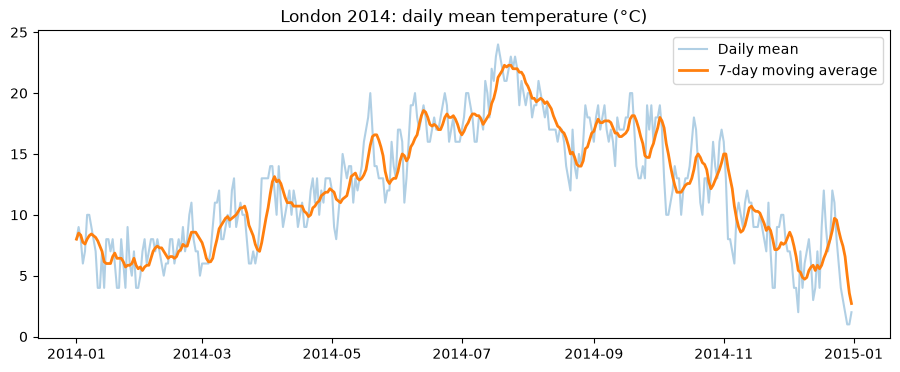

In [156]:
# The SQL did the maths; pandas/matplotlib do the presentation.
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(london_daily["day"], london_daily["mean_temp"], alpha=0.35, label="Daily mean")
    ax.plot(london_daily["day"], london_daily["temp_7d_avg"], linewidth=2, label="7-day moving average")
    ax.set_title("London 2014: daily mean temperature (°C)")
    ax.legend()
    plt.show()
except ImportError:
    print("matplotlib isn't installed. Run:  myenv/bin/python -m pip install matplotlib")

In [157]:
# 11.5 LAG / LEAD: compare with the previous or next row
# Day-over-day change, and month-over-month growth: the bread and butter of reporting.

q("""
    WITH monthly AS (
        SELECT Period, SUM([Trade Value (US$)]) AS exports_usd
        FROM week09.comtrade_milk_uk_monthly_14
        WHERE [Trade Flow] = 'Exports' AND Partner <> 'World'
        GROUP BY Period
    )
    SELECT Period,
           exports_usd,
           LAG(exports_usd) OVER (ORDER BY Period)                         AS prev_month_usd,
           ROUND(100.0 * (exports_usd - LAG(exports_usd) OVER (ORDER BY Period))
                 / NULLIF(LAG(exports_usd) OVER (ORDER BY Period), 0), 1) AS mom_growth_pct,
           SUM(exports_usd) OVER (ORDER BY Period ROWS UNBOUNDED PRECEDING) AS ytd_exports_usd
    FROM monthly
    ORDER BY Period
""")

,Period,exports_usd,prev_month_usd,mom_growth_pct,ytd_exports_usd
0,201401,87138654,NaN,NaN,87138654
1,201402,72489716,"87,138,654.00",-16.80,159628370
2,201403,86781424,"72,489,716.00",19.70,246409794
3,201404,95195778,"86,781,424.00",9.70,341605572
4,201405,96201135,"95,195,778.00",1.10,437806707
5,201406,99315900,"96,201,135.00",3.20,537122607
6,201407,72878716,"99,315,900.00",-26.60,610001323
7,201408,61737703,"72,878,716.00",-15.30,671739026
8,201409,60600293,"61,737,703.00",-1.80,732339319
9,201410,57003417,"60,600,293.00",-5.90,789342736


In [158]:
# 11.6 NTILE, percentiles and the median
# NTILE(4) splits rows into 4 equal-sized buckets (quartiles). This is ideal for segmentation such as "top 25% of spenders".
# PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY x) OVER (PARTITION BY ...) gives the median. In T-SQL it's a window function, so use DISTINCT to get one row per group.

q("""
    WITH q AS (
        SELECT Customer_ID, Annual_Income, Spending_Score,
               NTILE(4) OVER (ORDER BY Annual_Income) AS income_quartile
        FROM week19.customer_analytics_data
    )
    SELECT income_quartile,
           COUNT(*)                         AS customers,
           MIN(Annual_Income)               AS from_income,
           MAX(Annual_Income)               AS to_income,
           ROUND(AVG(1.0 * Spending_Score), 1) AS avg_spending_score
    FROM q
    GROUP BY income_quartile
    ORDER BY income_quartile
""")


,income_quartile,customers,from_income,to_income,avg_spending_score
0,1,125,"16,053.10","36,754.83",34.00
1,2,125,"36,777.38","43,466.96",45.50
2,3,125,"43,485.30","51,560.92",56.60
3,4,125,"51,618.47","73,202.80",55.90


In [159]:
q("""
    SELECT DISTINCT
        Region,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY Annual_Income) OVER (PARTITION BY Region) AS median_income,
        AVG(Annual_Income) OVER (PARTITION BY Region)                                          AS mean_income
    FROM week19.customer_analytics_data
    ORDER BY Region
""")

,Region,median_income,mean_income
0,East,"45,490.40","45,530.31"
1,North,"43,401.89","43,865.09"
2,South,"42,198.43","42,892.17"
3,West,"42,396.64","43,892.51"


In [160]:
# 11.7 De-duplication with ROW_NUMBER
# A very common real-world task is keeping one row per key, for example the latest record per customer.

q("""
    WITH d AS (
        SELECT Partner, Period, [Commodity Code], [Trade Value (US$)] AS value_usd,
               ROW_NUMBER() OVER (PARTITION BY Partner ORDER BY [Trade Value (US$)] DESC) AS rn
        FROM week09.comtrade_milk_uk_monthly_14
        WHERE [Trade Flow] = 'Exports' AND Partner <> 'World'
    )
    SELECT TOP 15 Partner, Period AS best_month, [Commodity Code], value_usd
    FROM d
    WHERE rn = 1
    ORDER BY value_usd DESC
""")


,Partner,best_month,Commodity Code,value_usd
0,Ireland,201401,0401,32069689
1,Algeria,201406,0402,22411564
2,Netherlands,201406,0402,7858429
3,Belgium,201401,0401,5663128
4,France,201403,0401,4712500
5,Nigeria,201408,0402,4676807
6,Germany,201410,0402,3765190
7,Yemen,201408,0402,3311725
8,China,201410,0402,3284240
9,Côte d'Ivoire,201403,0402,2842636


In [161]:
# Exercise 11.1. For each Preferred_Category in week19.customer_analytics_data, return the top 2 customers by Avg_Order_Value (category, customer, value, rank).

q("""
    WITH r AS (
        SELECT Preferred_Category, Customer_ID, Avg_Order_Value,
               DENSE_RANK() OVER (PARTITION BY Preferred_Category ORDER BY Avg_Order_Value DESC) AS rnk
        FROM week19.customer_analytics_data
    )
    SELECT * FROM r WHERE rnk <= 2 ORDER BY Preferred_Category, rnk
""")

,Preferred_Category,Customer_ID,Avg_Order_Value,rnk
0,Beauty,CID_0074,500.00,1
1,Beauty,CID_0409,500.00,1
2,Beauty,CID_0078,500.00,1
3,Beauty,CID_0001,500.00,1
4,Beauty,CID_0056,500.00,1
...,...,...,...,...
433,Sports,CID_0118,500.00,1
434,Sports,CID_0473,500.00,1
435,Sports,CID_0456,500.00,1
436,Sports,CID_0332,500.00,1


In [162]:
# Exercise 11.2. For London, find the 5 biggest day-to-day drops in Mean TemperatureC (today minus yesterday), showing both dates and both temperatures.

q("""
    WITH d AS (
        SELECT TRY_CONVERT(date, GMT) AS day, [Mean TemperatureC] AS temp,
               LAG(TRY_CONVERT(date, GMT)) OVER (ORDER BY TRY_CONVERT(date, GMT)) AS prev_day,
               LAG([Mean TemperatureC])    OVER (ORDER BY TRY_CONVERT(date, GMT)) AS prev_temp
        FROM week06.london_2014
    )
    SELECT TOP 5 prev_day, prev_temp, day, temp, temp - prev_temp AS change
    FROM d
    WHERE prev_temp IS NOT NULL
    ORDER BY change ASC
""")

,prev_day,prev_temp,day,temp,change
0,2014-06-03,16,2014-06-04,11,-5
1,2014-11-02,13,2014-11-03,8,-5
2,2014-03-09,12,2014-03-10,8,-4
3,2014-03-16,13,2014-03-17,9,-4
4,2014-10-03,17,2014-10-04,13,-4


In [163]:
# Exercise 11.3. Compute the cumulative rainfall per month for London (the running total resets every month). Show the last day of each month with its month-to-date total. (Hint: PARTITION BY month, then keep rows where the date equals EOMONTH.)

q("""
    WITH r AS (
        SELECT TRY_CONVERT(date, GMT) AS day,
               SUM(Precipitationmm) OVER (PARTITION BY MONTH(TRY_CONVERT(date, GMT))
                                          ORDER BY TRY_CONVERT(date, GMT)
                                          ROWS UNBOUNDED PRECEDING) AS mtd_rain_mm
        FROM week06.london_2014
    )
    SELECT day, mtd_rain_mm FROM r WHERE day = EOMONTH(day) ORDER BY day
""")

,day,mtd_rain_mm
0,2014-01-31,88.38
1,2014-02-28,50.55
2,2014-03-31,15.74
3,2014-04-30,30.99
4,2014-05-31,44.69
5,2014-06-30,26.93
6,2014-07-31,34.04
7,2014-08-31,81.27
8,2014-09-30,2.54
9,2014-10-31,36.07


In [164]:
# 12. Reshaping: PIVOT and UNPIVOT

# 12.1 PIVOT: long to wide

q("""
    SELECT Period, [Imports], [Exports], [Exports] - [Imports] AS trade_balance
    FROM (
        SELECT Period,
               CAST([Trade Flow] AS varchar(20)) AS flow,
               [Trade Value (US$)]               AS value_usd
        FROM week09.comtrade_milk_uk_monthly_14
        WHERE Partner <> 'World'
    ) AS src
    PIVOT (SUM(value_usd) FOR flow IN ([Imports], [Exports])) AS p
    ORDER BY Period
""")

,Period,Imports,Exports,trade_balance
0,201401,52374076,87138654,34764578
1,201402,39300067,72489716,33189649
2,201403,44319454,86781424,42461970
3,201404,44210607,95195778,50985171
4,201405,48075124,96201135,48126011
5,201406,45104304,99315900,54211596
6,201407,44796751,72878716,28081965
7,201408,40294833,61737703,21442870
8,201409,56702545,60600293,3897748
9,201410,56365543,57003417,637874


In [165]:
# 12.2 Unpivot (wide to long) with CROSS APPLY (VALUES ...)
# The London table stores Max, Mean and Min temperatures as three columns. For plotting or grouping, it's often easier as one measure / value pair per row. CROSS APPLY with a VALUES list is the modern and flexible way to do this. Unlike UNPIVOT, it keeps NULLs and lets you mix expressions.

long = q("""
    SELECT TRY_CONVERT(date, l.GMT) AS day, v.measure, v.temp_c
    FROM week06.london_2014 AS l
    CROSS APPLY (VALUES ('max',  l.[Max TemperatureC]),
                        ('mean', l.[Mean TemperatureC]),
                        ('min',  l.[Min TemperatureC])) AS v(measure, temp_c)
    WHERE MONTH(TRY_CONVERT(date, l.GMT)) = 7
    ORDER BY day, v.measure
""")
print(long.shape)   # 31 days × 3 measures = 93 rows
long.head(6)




(93, 3)


,day,measure,temp_c
0,2014-07-01,max,23
1,2014-07-01,mean,17
2,2014-07-01,min,12
3,2014-07-02,max,24
4,2014-07-02,mean,18
5,2014-07-02,min,11


In [166]:
# Exercise 12.1. Build a city × month table of average mean temperature, with one row per month and one column per city (London, Delhi, Moscow). Use either PIVOT or conditional aggregation over a UNION ALL.

q("""
    WITH t AS (
        SELECT 'London' AS city, MONTH(TRY_CONVERT(date, GMT)) AS m, [Mean TemperatureC] AS temp FROM week06.london_2014
        UNION ALL SELECT 'Delhi',  MONTH(TRY_CONVERT(date, [Date])), [Mean TemperatureC] FROM week06.delhi_del_2014
        UNION ALL SELECT 'Moscow', MONTH(TRY_CONVERT(date, [Date])), [Mean TemperatureC] FROM week06.moscow_svo_2014
    )
    SELECT m AS month_no,
           ROUND(AVG(CASE WHEN city = 'London' THEN 1.0 * temp END), 1) AS london,
           ROUND(AVG(CASE WHEN city = 'Delhi'  THEN 1.0 * temp END), 1) AS delhi,
           ROUND(AVG(CASE WHEN city = 'Moscow' THEN 1.0 * temp END), 1) AS moscow
    FROM t
    GROUP BY m
    ORDER BY m
""")

,month_no,london,delhi,moscow
0,1,6.60,-1.90,-9.60
1,2,7.30,2.30,-2.60
2,3,9.10,9.10,1.80
3,4,11.40,14.20,5.70
4,5,13.50,19.20,14.80
5,6,17.10,22.90,15.20
6,7,20.10,26.20,19.50
7,8,17.00,27.10,18.80
8,9,16.80,22.10,11.70
9,10,13.70,13.20,2.80


In [167]:
# 13. SQL + Python like a professional
# 13.1 Never paste user input into SQL: use parameters
# If a value comes from a variable, a widget or a user, don't build the SQL with an f-string. That's how SQL injection happens, and quotes in values (like Côte d'Ivoire) break the query anyway. Pass the value as a parameter and let the driver handle quoting:
                                                                                                                                                    
from sqlalchemy import text

partner = "France"     # imagine this came from a dropdown

safe = pd.read_sql(
    text("""
        SELECT Period, [Trade Flow], SUM([Trade Value (US$)]) AS value_usd
        FROM week09.comtrade_milk_uk_monthly_14
        WHERE Partner = :partner
        GROUP BY Period, [Trade Flow]
        ORDER BY Period, [Trade Flow]
    """),
    get_engine(),
    params={"partner": partner},
)
safe.head()



,Period,Trade Flow,value_usd
0,201401,Exports,3108416
1,201401,Imports,9542886
2,201402,Exports,2345627
3,201402,Imports,7938881
4,201403,Exports,5382092


### 14. Capstone: loan-approval risk briefing
You're an analyst at a lender. The Head of Credit wants a one-page briefing before Monday's credit committee. Use only SQL against week17.loan_approval_prediction (read-only, of course) to answer these five questions, then write a three-bullet summary in the markdown cell at the end.



In [169]:
# Baseline. How many applications, what's the overall approval rate, and how many rows have missing values in key fields?

q("""
    SELECT COUNT(*)                                                  AS applications,
           ROUND(100.0 * AVG(1.0 * Loan_Approved), 1)                AS approval_rate_pct,
           SUM(CASE WHEN Credit_History IS NULL THEN 1 ELSE 0 END)   AS missing_credit_history,
           SUM(CASE WHEN Loan_Amount    IS NULL THEN 1 ELSE 0 END)   AS missing_loan_amount,
           SUM(CASE WHEN Applicant_Income IS NULL THEN 1 ELSE 0 END) AS missing_income
    FROM week17.loan_approval_prediction
""")


,applications,approval_rate_pct,missing_credit_history,missing_loan_amount,missing_income
0,500,66.80,0,0,0


In [174]:
# Drivers. Approval rate by Credit_History × Previous_Loan_Status. Which combination is riskiest for the business, approved yet with a bad history?

q("""
    SELECT Credit_History, Previous_Loan_Status,
           COUNT(*)                                   AS applications,
           SUM(Loan_Approved)                         AS approved,
           ROUND(100.0 * AVG(1.0 * Loan_Approved), 1) AS approval_rate_pct
    FROM week17.loan_approval_prediction
    GROUP BY Credit_History, Previous_Loan_Status
    ORDER BY Credit_History, approval_rate_pct DESC
""")

,Credit_History,Previous_Loan_Status,applications,approved,approval_rate_pct
0,0,NaN,83,0,0.00
1,0,Defaulted,83,0,0.00
2,1,Paid,250,250,100.00
3,1,NaN,84,84,100.00


In [175]:
# Affordability. Create a loan_to_income ratio (Loan_Amount / (Applicant_Income + Coapplicant_Income), divide safely!). Bucket it into quartiles with NTILE(4) and show the approval rate per quartile.

q("""
    WITH ratio AS (
        SELECT Loan_Approved,
               1.0 * Loan_Amount
                   / NULLIF(COALESCE(Applicant_Income, 0) + COALESCE(Coapplicant_Income, 0), 0) AS loan_to_income
        FROM week17.loan_approval_prediction
        WHERE Loan_Amount IS NOT NULL
    ),
    bucketed AS (
        SELECT *, NTILE(4) OVER (ORDER BY loan_to_income) AS lti_quartile
        FROM ratio
        WHERE loan_to_income IS NOT NULL
    )
    SELECT lti_quartile,
           ROUND(MIN(loan_to_income), 2)              AS lti_from,
           ROUND(MAX(loan_to_income), 2)              AS lti_to,
           COUNT(*)                                   AS applications,
           ROUND(100.0 * AVG(1.0 * Loan_Approved), 1) AS approval_rate_pct
    FROM bucketed
    GROUP BY lti_quartile
    ORDER BY lti_quartile
""")

,lti_quartile,lti_from,lti_to,applications,approval_rate_pct
0,1,1.96,2.17,125,0.00
1,2,2.18,2.51,125,67.20
2,3,2.51,2.66,125,100.00
3,4,2.66,5.69,125,100.00


In [ ]:
# Segments. Rank Property_Area × Education segments by approval rate, and show each segment's gap versus the overall rate (window function or CTE).

q("""
    WITH seg AS (
        SELECT Property_Area, Education, COUNT(*) AS applications,
               AVG(1.0 * Loan_Approved) AS rate
        FROM week17.loan_approval_prediction
        GROUP BY Property_Area, Education
    )
    SELECT Property_Area, Education, applications,
           ROUND(100 * rate, 1)                                        AS approval_rate_pct,
           ROUND(100 * (rate - SUM(rate * applications) OVER () / SUM(applications) OVER ()), 1) AS pp_vs_overall,
           RANK() OVER (ORDER BY rate DESC)                            AS segment_rank
    FROM seg
    ORDER BY segment_rank
""")

,Property_Area,Education,applications,approval_rate_pct,pp_vs_overall,segment_rank
0,Semiurban,Graduate,167,100.00,33.20,1
1,Urban,Graduate,167,100.00,33.20,1
2,Rural,Not Graduate,166,0.00,-66.80,3


In [182]:
# Watch-list. Return the 10 largest approved loans where Credit_History = 0, each with its rank within its Property_Area.

q("""
    WITH w AS (
        SELECT Application_ID, Property_Area, Loan_Amount, Applicant_Income, Previous_Loan_Status,
               RANK() OVER (PARTITION BY Property_Area ORDER BY Loan_Amount DESC) AS rank_in_area
        FROM week17.loan_approval_prediction
        WHERE Loan_Approved = 1 AND Credit_History = 0
    )
    SELECT TOP 10 * FROM w ORDER BY Loan_Amount DESC
""")

,Application_ID,Property_Area,Loan_Amount,Applicant_Income,Previous_Loan_Status,rank_in_area


Finding 1: The Drivers. Every applicant with Credit_History = 1 was approved (334 out of 334, 100% approval rate), regardless of whether they previously defaulted or had no prior loan record. Every applicant with Credit_History = 0 was rejected (0 out of 166, 0% approval rate). This isn't risk-based lending. This is a single-variable pass/fail rule. Previous loan defaults are not influencing the decision at all, which is a serious gap in the underwriting logic.


Finding 2: Semiurban Graduates and Urban Graduates both have 100% approval rates, sitting 33.2 percentage points above the overall rate of 66.8%. Rural Non-Graduates have a 0% approval rate, sitting 66.8 percentage points below the overall. This suggests the approval model is effectively excluding an entire demographic segment rather than evaluating individual risk.


Finding 3: Quartile 1 (the lowest loan-to-income ratio, 1.96 to 2.17) has a 0% approval rate. Quartiles 3 and 4 (the highest ratios, 2.51 to 5.69) have 100% approval. Applicants borrowing the least relative to their income are being rejected, while those stretching the most are being approved. This suggests loan-to-income ratio is not driving decisions, or it's being overridden entirely by credit history and education.


Recommendation: The credit committee should commission a review of the approval algorithm. A single binary variable should not override all other risk indicators. Applicants with strong income, low loan-to-income ratios, and no previous defaults are being rejected solely because of one field. Conversely, applicants with prior defaults are being approved solely because Credit_History = 1. Introducing a weighted scoring model that considers multiple factors (income, affordability, loan history, employment) would produce more accurate risk decisions and reduce both false rejections and hidden exposure.


In [ ]:
# Learning Numpy

In [ ]:
# example  

import numpy as np  
arr = np.array([1, 2, 3, 4, 5])  
print(arr)  
print(type(arr)) 

[1 2 3 4 5]
<class 'numpy.ndarray'>


In [184]:

import numpy

In [185]:
# Checking Numpy Version

import numpy as np  
print(np.__version__)

2.5.4


In [186]:
#Creating an ndarray

import numpy as np  
arr = np.array([1, 2, 3, 4, 5])  
print(arr)  
print(type(arr))

[1 2 3 4 5]
<class 'numpy.ndarray'>


In [187]:
# Example: Create a 0-D array with value 42

import numpy as np  
arr = np.array(42)  
print(arr)

42


In [188]:
# Example: Create a 1-D array containing the values 1, 2, 3, 4, 5
import numpy as np  
arr = np.array([1, 2, 3, 4, 5])  
print(arr)

[1 2 3 4 5]


In [ ]:
# Example: Create a 2-D array containing two arrays with the values 1,2,3 and 4,5,6

import numpy as np  
arr = np.array([[1, 2, 3], [4, 5, 6]])  
print(arr)

[[1 2 3]
 [4 5 6]]


In [190]:
# Example: Create a 3-D array with two 2-D arrays, each containing two arrays with the values 1,2,3 and 4,5,6

import numpy as np  
arr = np.array([[[1, 2, 3], [4, 5, 6]], [[1, 2, 3], [4, 5, 6]]])  
print(arr) 

[[[1 2 3]
  [4 5 6]]

 [[1 2 3]
  [4 5 6]]]


In [191]:
# Example: Check how many dimensions the arrays have

import numpy as np  
a = np.array(42)  
b = np.array([1, 2, 3, 4, 5])  
c = np.array([[1, 2, 3], [4, 5, 6]])  
d = np.array([[[1, 2, 3], [4, 5, 6]], [[1, 2, 3], [4, 5, 6]]])  

print(a.ndim)  
print(b.ndim)  
print(c.ndim)  
print(d.ndim)



0
1
2
3


In [192]:
# Example: Create an array with 5 dimensions and verify that it has 5 dimensions
import numpy as np  
arr = np.array([1, 2, 3, 4], ndmin=5)  
print(arr)  
print('number of dimensions :', arr.ndim) 

[[[[[1 2 3 4]]]]]
number of dimensions : 5


In [193]:
# Example: Get the first element from the following array
import numpy as np  
arr = np.array([1, 2, 3, 4])  
print(arr[0]) 

1


In [194]:
# Example: Get the second element from the following array
import numpy as np  
arr = np.array([1, 2, 3, 4])  
print(arr[1]) 

2


In [195]:
### Example: Get third and fourth elements and add them  

import numpy as np  
arr = np.array([1, 2, 3, 4])  
print(arr[2] + arr[3]) 

7


In [196]:
# Example: Access the element on the first row, second column
import numpy as np  
arr = np.array([[1,2,3,4,5], [6,7,8,9,10]])  
print('2nd element on 1st row: ', arr[0, 1]) 

2nd element on 1st row:  2


In [197]:
### Example: Access the element on the second row, fifth column  

import numpy as np  
arr = np.array([[1,2,3,4,5], [6,7,8,9,10]])  
print('5th element on 2nd row: ', arr[1, 4])

5th element on 2nd row:  10


In [198]:
# Accessing Elements in 3-D Arrays  

# To access elements from 3-D arrays, use comma-separated integers representing each dimension.  

# Example: Access the third element of the second array of the first array  

import numpy as np  
arr = np.array([[[1, 2, 3], [4, 5, 6]], [[7, 8, 9], [10, 11, 12]]])  
print(arr[0, 1, 2]) 

6


In [201]:
# Negative Indexing  

# Use negative indexing to access elements from the end of an array.  

# Example: Print the last element from the 2nd row  

import numpy as np  
arr = np.array([[1,2,3,4,5], [6,7,8,9,10]])  
print('Last element from 2nd dim: ', arr[1, -1])

Last element from 2nd dim:  10


In [202]:
# Slice elements from index 1 to index 5
import numpy as np  
arr = np.array([1, 2, 3, 4, 5, 6, 7])  
print(arr[1:5])

[2 3 4 5]


In [203]:
# Slice elements from index 4 to the end
import numpy as np  
arr = np.array([1, 2, 3, 4, 5, 6, 7])  
print(arr[4:])

[5 6 7]


In [204]:
# Slice elements from the beginning to index 4 (not included)
import numpy as np  
arr = np.array([1, 2, 3, 4, 5, 6, 7])  
print(arr[:4]) 

[1 2 3 4]


In [205]:
# Negative Slicing
# Use the minus operator to refer to indexes from the end.

#Example: Slice from index 3 from the end to index 1 from the end
import numpy as np  

arr = np.array([1, 2, 3, 4, 5, 6, 7])  
print(arr[-3:-1]) 



[5 6]


In [206]:
# Using Step in Slicing
#Example: Return every other element from index 1 to index 5
import numpy as np  
arr = np.array([1, 2, 3, 4, 5, 6, 7])  
print(arr[1:5:2]) 

[2 4]


In [207]:
### Example: Return every other element from the entire array  

import numpy as np  
arr = np.array([1, 2, 3, 4, 5, 6, 7])  
print(arr[::2])

[1 3 5 7]


In [208]:
## Slicing 2-D Arrays  

### Example: From the second row, slice elements from index 1 to index 4 (not included)  

import numpy as np  
arr = np.array([[1, 2, 3, 4, 5], [6, 7, 8, 9, 10]])  
print(arr[1, 1:4]) 

[7 8 9]


In [213]:
### Example: From both rows, return index 2  

import numpy as np  
arr = np.array([[1, 2, 3, 4, 5], [6, 7, 8, 9, 10]])  
print(arr[0:2, 2]) 

[3 8]


In [214]:
### Example: From both rows, slice index 1 to index 4 (not included), returns a 2-D array  

import numpy as np  
arr = np.array([[1, 2, 3, 4, 5], [6, 7, 8, 9, 10]])  
print(arr[0:2, 1:4]) 

[[2 3 4]
 [7 8 9]]


In [215]:
# Example: Get the data type of an array object
import numpy as np  
arr = np.array([1, 2, 3, 4])  
print(arr.dtype)  

int64


In [216]:
# Example: Get the data type of an array containing strings  

import numpy as np  
arr = np.array(['apple', 'banana', 'cherry'])  
print(arr.dtype)

<U6


In [217]:
# Example: Create an array with data type string
import numpy as np  
arr = np.array([1, 2, 3, 4], dtype='S')  
print(arr)  
print(arr.dtype)

[b'1' b'2' b'3' b'4']
|S1


In [218]:
# Example: Create an array with data type 4 bytes integer
import numpy as np  
arr = np.array([1, 2, 3, 4], dtype='i4')  
print(arr)  
print(arr.dtype) 

[1 2 3 4]
int32


In [226]:
# Example: A non-integer string like 'a' cannot be converted to integer (will raise an error)
import numpy as np  
arr = np.array(['a', '2', '3'], dtype='i')  
# This will raise a ValueError  

ValueError: invalid literal for int() with base 10: 'a'

In [227]:
#Example: Change data type from float to integer by using 'i' as parameter value
import numpy as np  
arr = np.array([1.1, 2.1, 3.1])  
newarr = arr.astype('i')  
print(newarr)  
print(newarr.dtype)

[1 2 3]
int32


In [228]:
### Example: Change data type from float to integer by using `int` as parameter value  

import numpy as np  
arr = np.array([1.1, 2.1, 3.1])  
newarr = arr.astype(int)  
print(newarr)  
print(newarr.dtype) 

[1 2 3]
int64


In [229]:
### Example: Change data type from integer to boolean
import numpy as np  
arr = np.array([1, 0, 3])  
newarr = arr.astype(bool)  
print(newarr)  
print(newarr.dtype)

[ True False  True]
bool


In [230]:
#Example: Make a copy, change the original array, and display both arrays
import numpy as np  
arr = np.array([1, 2, 3, 4, 5])  
x = arr.copy()  
arr[0] = 42  

print(arr)  # [42  2  3  4  5]  
print(x)    # [1  2  3  4  5] 

[42  2  3  4  5]
[1 2 3 4 5]


In [ ]:
# Example: Make a view, change the original array, and display both arrays


import numpy as np  
arr = np.array([1, 2, 3, 4, 5])  
x = arr.view()  
arr[0] = 42  

print(arr)  # [42  2  3  4  5]  
print(x)    # [42  2  3  4  5]  

[42  2  3  4  5]
[42  2  3  4  5]


In [232]:
# Example: Make a view, change the view, and display both arrays

import numpy as np  
arr = np.array([1, 2, 3, 4, 5])  
x = arr.view()  
x[0] = 31  

print(arr)  # [31  2  3  4  5]  
print(x)    # [31  2  3  4  5] 

[31  2  3  4  5]
[31  2  3  4  5]


In [233]:
# Example: Print the value of the base attribute
import numpy as np  
arr = np.array([1, 2, 3, 4, 5])  
x = arr.copy()  
y = arr.view()  

print(x.base)  # None  
print(y.base)  # [1 2 3 4 5] 

None
[1 2 3 4 5]


In [234]:
# Example: Print the shape of a 2-D array
import numpy as np  
arr = np.array([[1, 2, 3, 4], [5, 6, 7, 8]])  
print(arr.shape)

(2, 4)


In [235]:
# Example: Create an array with 5 dimensions using ndmin, verify last dimension has value 4
import numpy as np  
arr = np.array([1, 2, 3, 4], ndmin=5)  
print(arr)  
print('shape of array :', arr.shape) 

[[[[[1 2 3 4]]]]]
shape of array : (1, 1, 1, 1, 4)


In [236]:
# Example: Convert a 1-D array with 12 elements into a 2-D array
#The outermost dimension will have 4 arrays, each with 3 elements:

import numpy as np  
arr = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])  
newarr = arr.reshape(4, 3)  
print(newarr) 

[[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]


In [237]:
# Example: Convert a 1-D array with 12 elements into a 3-D array
# The outermost dimension will have 2 arrays, each containing 3 arrays with 2 elements:

import numpy as np  
arr = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])  
newarr = arr.reshape(2, 3, 2)  
print(newarr)

[[[ 1  2]
  [ 3  4]
  [ 5  6]]

 [[ 7  8]
  [ 9 10]
  [11 12]]]


In [238]:
Example: Attempt to reshape a 1-D array with 8 elements to a (3, 3) array (will raise an error)
import numpy as np  
arr = np.array([1, 2, 3, 4, 5, 6, 7, 8])  
newarr = arr.reshape(3, 3)  
print(newarr)  # Raises ValueError 

SyntaxError: invalid syntax (1885073968.py, line 1)

In [ ]:
# Example: Check if the returned array is a copy or a view
import numpy as np  
arr = np.array([1, 2, 3, 4, 5, 6, 7, 8])  
print(arr.reshape(2, 4).base) 

[1 2 3 4 5 6 7 8]


In [241]:
#Example: Convert 1D array with 8 elements to 3D array with 2x2 elements
import numpy as np  
arr = np.array([1, 2, 3, 4, 5, 6, 7, 8])  
newarr = arr.reshape(2, 2, -1)  
print(newarr) 

[[[1 2]
  [3 4]]

 [[5 6]
  [7 8]]]


In [242]:
# Example: Convert the array into a 1D array
import numpy as np  
arr = np.array([[1, 2, 3], [4, 5, 6]])  
newarr = arr.reshape(-1)  
print(newarr) 

[1 2 3 4 5 6]


In [243]:
# Example: Iterate on the elements of a 1-D array
import numpy as np  
arr = np.array([1, 2, 3])  
for x in arr:  
    print(x) 

1
2
3


In [244]:
# Example: Iterate on the elements of a 2-D array (rows)
import numpy as np  
arr = np.array([[1, 2, 3], [4, 5, 6]])  
for x in arr:  
    print(x) 

[1 2 3]
[4 5 6]


In [245]:
# To access each scalar element, you need to nest the loops:  

### Example: Iterate on each scalar element of the 2-D array  

import numpy as np  
arr = np.array([[1, 2, 3], [4, 5, 6]])  
for x in arr:  
    for y in x:  
        print(y) 

1
2
3
4
5
6


In [246]:
## Iterating 3-D Arrays  

# When you iterate over a 3-D array, you iterate over its 2-D arrays.  

### Example: Iterate on the elements of a 3-D array (2-D arrays)  

import numpy as np  
arr = np.array([[[1, 2, 3], [4, 5, 6]], [[7, 8, 9], [10, 11, 12]]])  
for x in arr:  
    print(x)

[[1 2 3]
 [4 5 6]]
[[ 7  8  9]
 [10 11 12]]


In [247]:
# To iterate down to scalars, nest the loops:  

### Example: Iterate down to the scalar elements  

import numpy as np  
arr = np.array([[[1, 2, 3], [4, 5, 6]], [[7, 8, 9], [10, 11, 12]]])  
for x in arr:  
    for y in x:  
        for z in y:  
            print(z) 

1
2
3
4
5
6
7
8
9
10
11
12


In [248]:
# Example: Iterate through each scalar of a 3-D array
import numpy as np  
arr = np.array([[[1, 2], [3, 4]], [[5, 6], [7, 8]]])  
for x in np.nditer(arr):  
    print(x)

1
2
3
4
5
6
7
8


In [249]:
# Example: Iterate through the array as strings
import numpy as np  
arr = np.array([1, 2, 3])  
for x in np.nditer(arr, flags=['buffered'], op_dtypes=['S']):  
    print(x)  

np.bytes_(b'1')
np.bytes_(b'2')
np.bytes_(b'3')


In [250]:
## Iterating With Different Step Size  

# You can use slicing to skip elements, then iterate as usual.  

### Example: Iterate through every scalar of a 2D array, skipping 1 element (step size 2)  

import numpy as np  
arr = np.array([[1, 2, 3, 4], [5, 6, 7, 8]])  
for x in np.nditer(arr[:, ::2]):  
    print(x)

1
3
5
7


In [251]:
# Example: Enumerate elements of a 1-D array
import numpy as np  
arr = np.array([1, 2, 3])  
for idx, x in np.ndenumerate(arr):  
    print(idx, x)
    

(0,) 1
(1,) 2
(2,) 3


In [252]:
### Example: Enumerate elements of a 2-D array  

import numpy as np  
arr = np.array([[1, 2, 3, 4], [5, 6, 7, 8]])  
for idx, x in np.ndenumerate(arr):  
    print(idx, x)

(0, 0) 1
(0, 1) 2
(0, 2) 3
(0, 3) 4
(1, 0) 5
(1, 1) 6
(1, 2) 7
(1, 3) 8


In [253]:
# Example: Join Two 1-D Arrays
import numpy as np  
arr1 = np.array([1, 2, 3])  
arr2 = np.array([4, 5, 6])  
arr = np.concatenate((arr1, arr2))  
print(arr)

[1 2 3 4 5 6]


In [254]:
# ## Example: Join Two 2-D Arrays Along Rows (axis=1)  

import numpy as np  
arr1 = np.array([[1, 2], [3, 4]])  
arr2 = np.array([[5, 6], [7, 8]])  
arr = np.concatenate((arr1, arr2), axis=1)  
print(arr)

[[1 2 5 6]
 [3 4 7 8]]


In [255]:
# Example: Stack Two 1-D Arrays Along a New Axis
import numpy as np  
arr1 = np.array([1, 2, 3])  
arr2 = np.array([4, 5, 6])  
arr = np.stack((arr1, arr2), axis=1)  
print(arr)

[[1 4]
 [2 5]
 [3 6]]


In [256]:
# ## Stacking Along Rows  

# NumPy provides a helper function: `hstack()` to stack along rows (horizontally).  

### Example:  

import numpy as np  
arr1 = np.array([1, 2, 3])  
arr2 = np.array([4, 5, 6])  
arr = np.hstack((arr1, arr2))  
print(arr) 

[1 2 3 4 5 6]


In [257]:
## Stacking Along Columns  

# NumPy provides a helper function: `vstack()` to stack along columns (vertically).  

### Example:  

import numpy as np  
arr1 = np.array([1, 2, 3])  
arr2 = np.array([4, 5, 6])  
arr = np.vstack((arr1, arr2))  
print(arr) 

[[1 2 3]
 [4 5 6]]


In [258]:
## Stacking Along Height (Depth)  

# NumPy provides a helper function: `dstack()` to stack along the third axis (height/depth).  

### Example:  

import numpy as np  
arr1 = np.array([1, 2, 3])  
arr2 = np.array([4, 5, 6])  
arr = np.dstack((arr1, arr2))  
print(arr) 

[[[1 4]
  [2 5]
  [3 6]]]


In [259]:
# this code conceals irrelevant warning messages
import warnings
warnings.simplefilter('ignore', FutureWarning)
import numpy as np

In [260]:
# this code conceals irrelevant warning messages
import warnings
warnings.simplefilter('ignore', FutureWarning)
import numpy as np

In [261]:
# Exercise Notebook (DS)



In [262]:
# Numpy 2D Array
a = np.array([[1,2,3],[3,4,5]])
print(a)

[[1 2 3]
 [3 4 5]]


In [263]:
# Base Ball Player's Heights AS a in 2D 
a = np.array([[1,2,3], [4,1,5]]) 
print (a)

[[1 2 3]
 [4 1 5]]


In [264]:
# Addition
a+3

array([[4, 5, 6],
       [7, 4, 8]])

In [265]:
# Multiplication
a*2

array([[ 2,  4,  6],
       [ 8,  2, 10]])

In [266]:
# Subtraction
a-2

array([[-1,  0,  1],
       [ 2, -1,  3]])

In [267]:
# Division
a/3

array([[0.33333333, 0.66666667, 1.        ],
       [1.33333333, 0.33333333, 1.66666667]])

In [268]:
# Subsetting 2D NumPy Arrays

a[0]

array([1, 2, 3])

In [269]:
a[0][0] # Accessing the first element from the first array

np.int64(1)

In [270]:
a[0][1:2] # Accessing from index 1 to 2 elements from the first array

array([2])

In [271]:
a[1][1:2] # Accessing from index 1 to 2 elements from the second array

array([1])

In [272]:
# Multiplication
a*2

array([[ 2,  4,  6],
       [ 8,  2, 10]])

In [273]:
# Subtraction
a-2

array([[-1,  0,  1],
       [ 2, -1,  3]])

In [274]:
# Division
a/3

array([[0.33333333, 0.66666667, 1.        ],
       [1.33333333, 0.33333333, 1.66666667]])

In [ ]:


a = np.arange(9, dtype = np.float_).reshape(3,3) 

print('First array:') 
a  

AttributeError: `np.float_` was removed in the NumPy 2.0 release. Use `np.float64` instead.

In [276]:
print('Second array:' )
b = np.array([10,10,10]) 
b

Second array:


array([10, 10, 10])

In [277]:
print('Add the two arrays:') 
np.add(a,b)  

Add the two arrays:


array([[11, 12, 13],
       [14, 11, 15]])

In [278]:
print('Subtract the two arrays:') 
np.subtract(a,b)

Subtract the two arrays:


array([[-9, -8, -7],
       [-6, -9, -5]])

In [279]:
print('Multiply the two arrays:') 
np.multiply(a,b)

Multiply the two arrays:


array([[10, 20, 30],
       [40, 10, 50]])

In [280]:
print('Divide the two arrays:' )
np.divide(a,b)

Divide the two arrays:


array([[0.1, 0.2, 0.3],
       [0.4, 0.1, 0.5]])

In [281]:
a = np.array([[3,7,5],[8,4,3],[2,4,9]]) 

print('Our array is:' )
a

Our array is:


array([[3, 7, 5],
       [8, 4, 3],
       [2, 4, 9]])

In [282]:
print('Applying amin() function:') 
np.amin(a,1)

Applying amin() function:


array([3, 3, 2])

In [283]:
print('Applying amin() function again:') 
np.amin(a,0) 

Applying amin() function again:


array([2, 4, 3])

In [284]:
print('Applying amax() function:') 
np.amax(a)

Applying amax() function:


np.int64(9)

In [285]:
print('Applying amax() function again:') 
np.amax(a, axis = 0)

Applying amax() function again:


array([8, 7, 9])

In [286]:
a = np.array([[3,7,5],[8,4,3],[2,4,9]]) 

print('Our array is:') 
a

Our array is:


array([[3, 7, 5],
       [8, 4, 3],
       [2, 4, 9]])

In [287]:
print('Applying ptp() function:') 
np.ptp(a) 

Applying ptp() function:


np.int64(7)

In [288]:
print('Applying ptp() function along axis 1:') 
np.ptp(a, axis = 1) 

Applying ptp() function along axis 1:


array([4, 5, 7])

In [289]:
print('Applying ptp() function along axis 0:')
np.ptp(a, axis = 0)

Applying ptp() function along axis 0:


array([6, 3, 6])

In [290]:
a = np.array([[30,40,70],[80,20,10],[50,90,60]])
a

array([[30, 40, 70],
       [80, 20, 10],
       [50, 90, 60]])

In [291]:
print('Applying percentile() function:') 
np.percentile(a,50)

Applying percentile() function:


np.float64(50.0)

In [292]:
print('Applying percentile() function along axis 1:') 
np.percentile(a,50, axis = 1)

Applying percentile() function along axis 1:


array([40., 20., 60.])

In [293]:
a = np.array([[30,65,70],[80,95,10],[50,90,60]]) 

print('Our array is:') 
a  

Our array is:


array([[30, 65, 70],
       [80, 95, 10],
       [50, 90, 60]])

In [294]:
print('Applying median() function:') 
np.median(a) 

Applying median() function:


np.float64(65.0)

In [295]:
print('Applying median() function along axis 0:') 
np.median(a, axis = 0)

Applying median() function along axis 0:


array([50., 90., 60.])

In [296]:
a = np.array([[1,2,3],[3,4,5],[4,5,6]]) 

print('Our array is:') 
a  

Our array is:


array([[1, 2, 3],
       [3, 4, 5],
       [4, 5, 6]])

In [297]:
print('Applying mean() function:') 
print(np.mean(a)) 

Applying mean() function:
3.6666666666666665


In [298]:
print('Applying mean() function along axis 0:') 
np.mean(a, axis = 0)

Applying mean() function along axis 0:


array([2.66666667, 3.66666667, 4.66666667])

In [299]:
print('Applying mean() function along axis 1:') 
np.mean(a, axis = 1)

Applying mean() function along axis 1:


array([2., 4., 5.])

In [300]:
a = np.array([1,2,3,4]) 

print('Our array is:') 
a  

Our array is:


array([1, 2, 3, 4])

In [301]:
print('Applying average() function:') 
np.average(a) 

Applying average() function:


np.float64(2.5)

In [302]:
# this is same as mean when weight is not specified 
wts = np.array([4,3,2,1]) 

In [303]:
print('Applying average() function again:') 
np.average(a,weights = wts)

Applying average() function again:


np.float64(2.0)

In [304]:
# Returns the sum of weights, if the returned parameter is set to True. 
print('Sum of weights') 
np.average([1,2,3, 4],weights = [4,3,2,1], returned = True)

Sum of weights


(np.float64(2.0), np.float64(10.0))

In [306]:
print('Second array:' )
b = np.array([10,10,10]) 
b

Second array:


array([10, 10, 10])